# Verizon Device Financing: Risk Model Review

*Data: 300,000 simulated applications, 1 Jan 2023 to 31 Dec 2024. Each answer is followed by the code and output that support it.*

## Executive summary

- **Verizon changed its approval logic on 1 Aug 2023 (loosening for the promotion) and on 1 May 2024 (tightening).** Both changes came from the score and its cut-offs. The applicant pool did not change at either date.
- **Defaults rose by about 55% on 1 May 2024 for applicants with the same risk profile.** Repayment behaviour got worse. The tightening did not cause the rise; it slightly offset it.
- **The internal risk score (IRS) ranks default risk better than credit score alone** (holdout AUC 0.590 vs 0.563). A simple logistic model using credit score, income, two age steps, existing-customer status and a regime indicator does better again (AUC 0.620) and is well calibrated.
- **Verizon is far too conservative given its own economics.** A funded plan earns +25% of device price if it is repaid and loses 35% if it defaults, so the break-even default probability is **41.7%**. The riskiest tenth of funded plans in the final regime defaults at 17%.
- **Counteroffers lose money.** Larger down payments and device downgrades do not reduce default, but they drive away 35–50% of the customers who receive them.
- **Recommendation: increase approvals, in steps.** (1) Approve conditional applicants on the terms they asked for (about +$1.0M). (2) Move the deny cut-off back to the 2023–24 level, where we have real outcome data (+$0.25M to +$1.1M). (3) Run a randomised test above that level. Together, (1) and (2) add about $2.1M (+18%) to the final regime's $12.0M profit.

## Setup

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 250)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 50)

HERE = Path.cwd()   # run the notebook from the Verizon EDA folder
DATA = HERE / "FEED Data" / "Verizon Data.csv"
DICT = HERE / "FEED Data" / "Verizon data dictionary.xlsx"

BREAK1 = pd.Timestamp("2023-08-01")
BREAK2 = pd.Timestamp("2024-05-01")


def section(title):
    print("\n" + "=" * 100 + f"\n{title}\n" + "=" * 100)

## 0. Data inspection and conventions

**Files.** `FEED Data/Verizon Data.csv` (the applications file; 300,000 rows × 18 columns) and `FEED Data/Verizon data dictionary.xlsx`.

| Column | dtype | Notes |
|---|---|---|
| application_date | date | 727 distinct days. Four days have no applications: Thanksgiving and Christmas in each year |
| race, hisp, gender | string | Self-reported, includes "PreferNot". For fairness evaluation only, so not used as predictors |
| age | int | 18–79 |
| income | float | $15,000–$200,000. Has spikes at the floor (2,116 rows) and the cap (2,229), which suggests the values are censored there |
| credit_score | int | 327–850 |
| existing_customer | int 0/1 | 40% are existing customers |
| device_requested / device_final | string | Low / Mid / High |
| device_price | int | $379–$1,219 (five prices per tier) |
| down_payment_base / final | float | Share of device price. **`down_payment_base` is exactly 0.205 − 0.00015 × credit_score (R² = 1)**, so it carries no information beyond credit score |
| internal_risk_score | float | Mean 0, SD 1; **higher = riskier**. The observed range (−4.06 to 4.36) differs from the dictionary's (−3.74 to 6.87) |
| initial_decision / final_status | string | See below |
| default_flag | float | **The only column with missing values: 34,940 missing** |
| profit | float | 0 for plans that were not funded |

**How the decision columns fit together**

| initial_decision | Funded_Original | Funded_Revised | Not_Funded |
|---|---|---|---|
| Approve | 242,673 | 0 | 0 |
| Conditional (counteroffer) | 0 | 22,387 | 16,706 |
| Deny | 0 | 0 | 18,234 |

- **Funded** = `Funded_Original` + `Funded_Revised` (265,060 plans). These are the only plans with an observed `default_flag`. The overall default rate is 8.03%.
- **Not funded** = `Not_Funded` (34,940): applicants who were denied, plus conditional applicants who turned down the counteroffer. `default_flag` is missing for all of them, and `profit` is 0.
- **Profit is a fixed share of device price:** +0.25 × price if the plan is repaid and −0.35 × price if it defaults, exactly, in every row and every regime. The down payment does not enter Verizon's profit estimate.

**Regimes** (dates found in Q4a; used throughout):

| Regime | Dates | Applications | Approve rate | Funded rate | Default rate (funded) |
|---|---|---|---|---|---|
| R1: baseline | 2023-01-01 to 2023-07-31 | 87,469 | 81.5% | 88.7% | 6.95% |
| R2: promotion (looser) | 2023-08-01 to 2024-04-30 | 112,251 | 88.9% | 93.8% | 6.75% |
| R3: tightened | 2024-05-01 to 2024-12-31 | 100,280 | 71.4% | 81.9% | 10.69% |

In [2]:
# --------------------------------------------------------------------------------------------
# 0. Load and inspect
# --------------------------------------------------------------------------------------------
section("0. DATA INSPECTION")
dd = pd.read_excel(DICT)
print(dd.to_string())
df = pd.read_csv(DATA, parse_dates=["application_date"])
print("shape", df.shape)
print(df.dtypes)
print("missing:\n", df.isna().sum()[df.isna().sum() > 0])
print(pd.crosstab(df.initial_decision, df.final_status, margins=True))
print("missing days:", pd.date_range("2023-01-01", "2024-12-31").difference(df.application_date.unique()).date)

df["regime"] = np.select([df.application_date < BREAK1, df.application_date < BREAK2], ["R1", "R2"], "R3")
df["funded"] = (df.final_status != "Not_Funded").astype(int)
df["approve"] = (df.initial_decision == "Approve").astype(int)
df["log_inc"] = np.log(df.income)
df["downgrade"] = (df.device_requested != df.device_final).astype(int)
df["dp_increase"] = df.down_payment_final - df.down_payment_base
df["year"] = df.application_date.dt.year
df["month"] = df.application_date.dt.month
f = df[df.funded == 1].copy()          # funded = Funded_Original + Funded_Revised (default_flag observed)
nf = df[df.funded == 0].copy()         # not funded = default_flag missing

print(df.groupby("regime").agg(start=("application_date", "min"), end=("application_date", "max"),
                               n=("age", "size"), approve=("approve", "mean"), funded=("funded", "mean")))

# profit structure (needed in Q7/Q8)
f["margin"] = f.profit / f.device_price
print(f.groupby("default_flag").margin.agg(["min", "max", "mean"]))
f["cs_band"] = pd.cut(f.credit_score, [0, 550, 600, 650, 700, 900])   # used in Q2 and Q4e


0. DATA INSPECTION
            Column name       Type                  Min                  Max                                                                                                          Meaning
0      application_date       Date  2023-01-01 00:00:00  2024-12-31 00:00:00                                                               Date at which application reached its final status
1                  race  Character                Asian                White                                      Self-identified applicant race (including "TwoMore" and "PreferNot" values)
2                  hisp  Character                 Hisp            PreferNot                         Self-identified applicant Hispanic/Non-Hispanic ethnicity (including "PreferNot" values)
3                gender  Character               Female            PreferNot                                                  Self-identified applicant gender (including "PreferNot" values)
4                   age    Int

shape (300000, 18)
application_date       datetime64[us]
race                              str
hisp                              str
gender                            str
age                             int64
income                        float64
credit_score                    int64
existing_customer               int64
device_requested                  str
device_final                      str
device_price                    int64
down_payment_base             float64
down_payment_final            float64
internal_risk_score           float64
initial_decision                  str
final_status                      str
default_flag                  float64
profit                        float64
dtype: object
missing:
 default_flag    34940
dtype: int64
final_status      Funded_Original  Funded_Revised  Not_Funded     All
initial_decision                                                     
Approve                    242673               0           0  242673
Conditional                 

## Regime determination (Q4a, done first)

The regimes are used in every question, so the break dates are found here before anything else. The written answer to Q4a is in the Q4 section.


Q4a. STRUCTURAL BREAKS


                    n    irs  approve   deny  default       cs  irs_resid
application_date                                                         
2023-07-26        455 -0.034    0.813  0.059    0.086  609.745      0.005
2023-07-27        429  0.017    0.776  0.093    0.092  606.704      0.016
2023-07-28        396  0.009    0.788  0.056    0.065  608.101      0.012
2023-07-29        404 -0.061    0.827  0.042    0.070  612.054     -0.008
2023-07-30        402 -0.023    0.821  0.055    0.059  608.687     -0.012
2023-07-31        380 -0.009    0.829  0.066    0.076  607.463      0.020
2023-08-01        398 -0.289    0.912  0.013    0.063  611.196     -0.221
2023-08-02        419 -0.320    0.907  0.019    0.048  610.169     -0.274
2023-08-03        422 -0.121    0.863  0.024    0.059  600.751     -0.231
2023-08-04        403 -0.226    0.883  0.020    0.095  607.871     -0.227
2023-08-05        410 -0.201    0.898  0.022    0.090  605.298     -0.224
2023-08-06        381 -0.274    0.895 

R1 {'Intercept': 13.9165, 'C(device_requested)[T.Low]': -0.0006, 'C(device_requested)[T.Mid]': -0.0018, 'credit_score': -0.0115, 'log_inc': -0.6217, 'age': 0.0002, 'existing_customer': -0.3834} R2= 0.824


R2 {'Intercept': 13.5138, 'C(device_requested)[T.Low]': 0.0047, 'C(device_requested)[T.Mid]': 0.0014, 'credit_score': -0.0115, 'log_inc': -0.6086, 'age': 0.0001, 'existing_customer': -0.3835} R2= 0.819


R3 {'Intercept': 14.0822, 'C(device_requested)[T.Low]': -0.0021, 'C(device_requested)[T.Mid]': 0.0009, 'credit_score': -0.0115, 'log_inc': -0.61, 'age': 0.0001, 'existing_customer': -0.3838} R2= 0.821


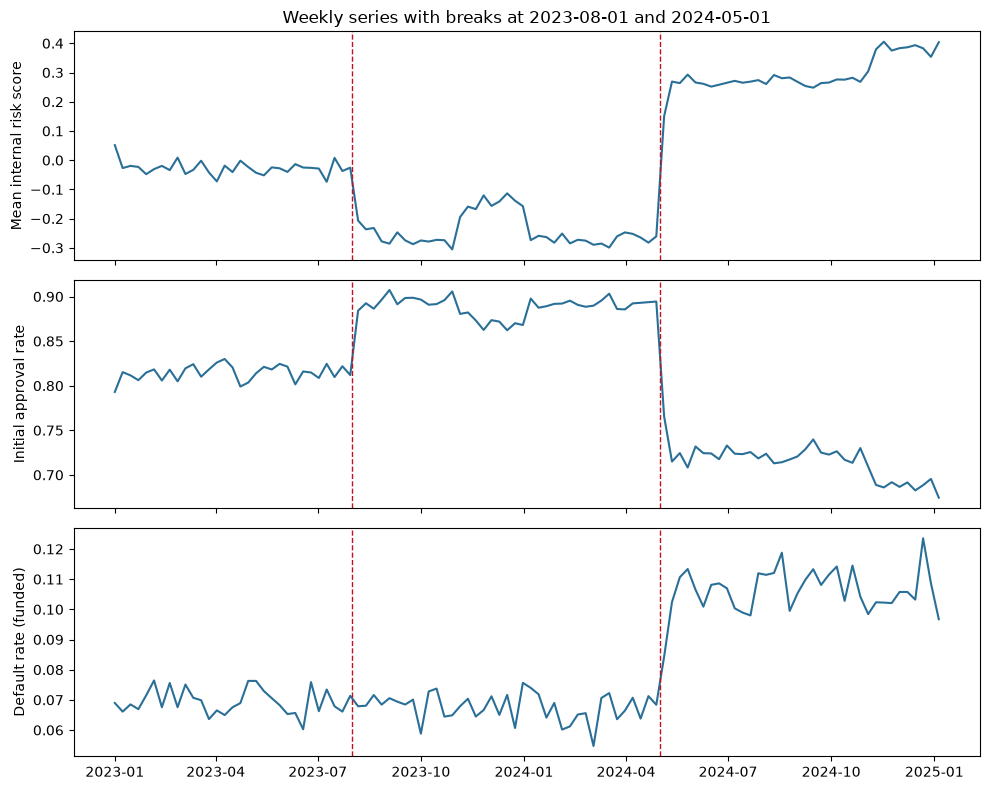

In [3]:
# --------------------------------------------------------------------------------------------
# 4a. Structural breaks (computed first; everything else uses the regimes)
# --------------------------------------------------------------------------------------------
section("Q4a. STRUCTURAL BREAKS")
daily = df.groupby("application_date").agg(n=("age", "size"), irs=("internal_risk_score", "mean"),
                                            approve=("approve", "mean"),
                                            deny=("initial_decision", lambda s: (s == "Deny").mean()),
                                            default=("default_flag", "mean"), cs=("credit_score", "mean"))
# residual score: IRS minus what applicant characteristics predict (fit on R1 only)
irs_fit = smf.ols("internal_risk_score ~ credit_score + log_inc + age + existing_customer + C(device_requested)",
                  df[df.regime == "R1"]).fit()
df["irs_resid"] = df.internal_risk_score - irs_fit.predict(df)
daily["irs_resid"] = df.groupby("application_date").irs_resid.mean()
for b in [BREAK1, BREAK2]:
    print(daily.loc[b - pd.Timedelta(days=6): b + pd.Timedelta(days=5)].round(3).to_string())

# search: the single day that maximises the before/after difference in the daily residual score
def best_split(series, lo, hi):
    out = {}
    for d in series.loc[lo:hi].index:
        out[d] = abs(series.loc[d:d + pd.Timedelta(days=30)].mean() - series.loc[d - pd.Timedelta(days=30):d - pd.Timedelta(days=1)].mean())
    return max(out, key=out.get), max(out.values())
print("best split 2023:", best_split(daily.irs_resid, "2023-03-01", "2023-12-01"))
print("best split 2024:", best_split(daily.irs_resid, "2024-02-01", "2024-11-30"))

print("decision thresholds by regime (min/max IRS per initial_decision):")
print(df.groupby(["regime", "initial_decision"]).internal_risk_score.agg(["min", "max", "count"]).round(3))
for r, g in df.groupby("regime"):
    m = smf.ols("internal_risk_score ~ credit_score + log_inc + age + existing_customer + C(device_requested)", g).fit()
    print(r, m.params.round(4).to_dict(), "R2=", round(m.rsquared, 3))

wk = df.set_index("application_date").resample("W")
weekly = pd.DataFrame({"irs": wk.internal_risk_score.mean(), "approve": wk.approve.mean(),
                       "default": wk.default_flag.mean(), "cs": wk.credit_score.mean()})
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for a, col, lab in zip(ax, ["irs", "approve", "default"],
                       ["Mean internal risk score", "Initial approval rate", "Default rate (funded)"]):
    a.plot(weekly.index, weekly[col], color="#2a6f97")
    a.set_ylabel(lab)
    for b in [BREAK1, BREAK2]:
        a.axvline(b, color="#c1121f", ls="--", lw=1)
ax[0].set_title("Weekly series with breaks at 2023-08-01 and 2024-05-01")
fig.tight_layout(); plt.show()

## Q1. Age

### Q1a. Which ages are over-represented?

**Conclusion: ages 18, 21, 25, 30, 40 and 65 are heavily over-represented, and 79 is likely a top-code. These peaks are not realistic.** A real applicant population changes smoothly from one year of age to the next. Spikes at round or milestone ages are a sign of self-reported or estimated ages, rounding, or form defaults. The spike at 18 is most likely a floor value (minimum eligible age, or a default entry).

| Age | Count | Average of the two neighbouring ages | Ratio |
|---|---|---|---|
| 18 | 14,425 | (19: 2,561) | 5.6× age 19 |
| 21 | 8,130 | 3,369 | 2.4× |
| 25 | 10,899 | 5,148 | 2.1× |
| 30 | 13,340 | 7,366 | 1.8× |
| 40 | 14,021 | 9,008 | 1.6× |
| 65 | 3,150 | 755 | 4.2× |
| 79 | 84 | (78: 30) | 2.8× age 78, likely a top-code |

The ages just next to each spike are depleted (for example, 19 and 20 are under 0.6× their neighbours, and 64 and 66 are 0.44× and 0.33×). This pattern is what you see when true ages are being shifted onto the round number. Within each spike, credit score and income look like the neighbouring ages (similar means and spreads), so the heaped records come from people near that age, not from random ages.


### Q1b. Does default risk change smoothly with age?

**Conclusion: default risk changes in steps, at 25 and at 67.** In between it is almost flat.

| Age band | Funded plans | Default rate |
|---|---|---|
| 18–24 | 29,755 | **11.9%** (every single year from 18 to 24 is between 11.6% and 12.4%) |
| 25–66 | 232,978 | **7.5%** (8.3% at 25, drifting down gently to about 7% in the 60s) |
| 67+ | 2,327 | **9.4%** |

The step is sharp. The default rate is 11.9% at age 24 and 8.3% at age 25, and 7.0% at 65, 8.0% at 66 and 10.2% at 67. A model with only the two step dummies fits better than a quadratic in age with the same number of parameters (log-likelihood −73,750 vs −73,775). The steps stay significant after controlling for credit score and income (age < 25: +0.36 log-odds; age ≥ 67: +0.38).

### Q1c. Why the smooth-vs-bucket choice matters more here

The choice matters more here because the steps in risk fall right where the applicants are piled up.

1. **The true risk curve is a step, not a curve.** A smooth fit spreads the 3.6-point drop at 25 over many years. A quadratic predicts 10.8% at age 21 (actual 12.0%), 9.6% at 25 (actual 8.3%) and 8.0% at 67 (actual 10.2%). So it underprices the young and the over-67s and overprices people in their late 20s.
2. **The largest age spikes sit on or next to the step.** Age 25 has 10,899 applicants (3.6% of everyone), more than any other age under 30. Age 65, just below the upper step, is a 4× spike. Where the bucket boundary goes decides how thousands of people are classified at once. With a cut at "< 25", the high-risk bucket defaults at 11.9%. With a cut at "≤ 25", the 25-year-olds are pulled into that bucket and its rate falls to 11.1%. Moving the boundary by one year changes the prediction for about 11,000 applicants by about 4 points.
3. **Ages near the step are the least reliable.** The spikes show that ages are rounded or misreported, and a cliff-edge rule rewards that. Stating "25" instead of "24" lowers predicted risk by a third. If Verizon uses age steps, it should verify date of birth near the cut-offs.


Q1. AGE
         n  neighbor_avg  ratio  n_funded  default   credit
age                                                        
18   14425           NaN    NaN      9994    0.116  567.985
19    2561        8709.5  0.294      1835    0.116  571.889
20    2994        5345.5  0.560      2140    0.122  571.342
21    8130        3368.5  2.414      6032    0.120  573.620
22    3743        6209.5  0.603      2770    0.121  574.928
23    4289        4209.5  1.019      3323    0.124  578.439
24    4676        7594.0  0.616      3661    0.119  580.032
25   10899        5148.0  2.117      8737    0.083  583.090
26    5620        8486.5  0.662      4528    0.081  584.115
27    6074        6043.0  1.005      4917    0.080  586.367
28    6466        6484.5  0.997      5393    0.082  588.728
29    6895        9903.0  0.696      5796    0.078  588.919
30   13340        7365.5  1.811     11363    0.080  591.867
31    7836       10659.5  0.735      6708    0.079  593.965
32    7979        8131.0  0.981

default_flag ~ age + I(age**2)                                                   LL=-73774.5 AIC=147554.9 {'age': -0.057, 'I(age ** 2)': 0.001}


default_flag ~ age_lt25 + age_ge67                                               LL=-73749.7 AIC=147505.4 {'age_lt25': 0.507, 'age_ge67': 0.24}


default_flag ~ age + I(age**2) + age_lt25 + age_ge67                             LL=-73721.1 AIC=147452.3 {'age': -0.011, 'I(age ** 2)': 0.0, 'age_lt25': 0.364, 'age_ge67': 0.381}


default_flag ~ credit_score + log_inc + age + I(age**2)                          LL=-73362.0 AIC=146734.0 {'age': -0.052, 'I(age ** 2)': 0.001}


default_flag ~ credit_score + log_inc + age + I(age**2) + age_lt25 + age_ge67    LL=-73308.6 AIC=146631.3 {'age': -0.006, 'I(age ** 2)': 0.0, 'age_lt25': 0.364, 'age_ge67': 0.381}
age          22         23         24         25         26         27
mean     0.1209     0.1243     0.1185     0.0826     0.0813     0.0803
size  2770.0000  3323.0000  3661.0000  8737.0000  4528.0000  4917.0000
age         63        64         65        66        67        68     69        70
mean    0.0736    0.0676     0.0702    0.0797    0.1023    0.0863    0.1    0.0951
size  992.0000  888.0000  3090.0000  590.0000  479.0000  394.0000  300.0  263.0000


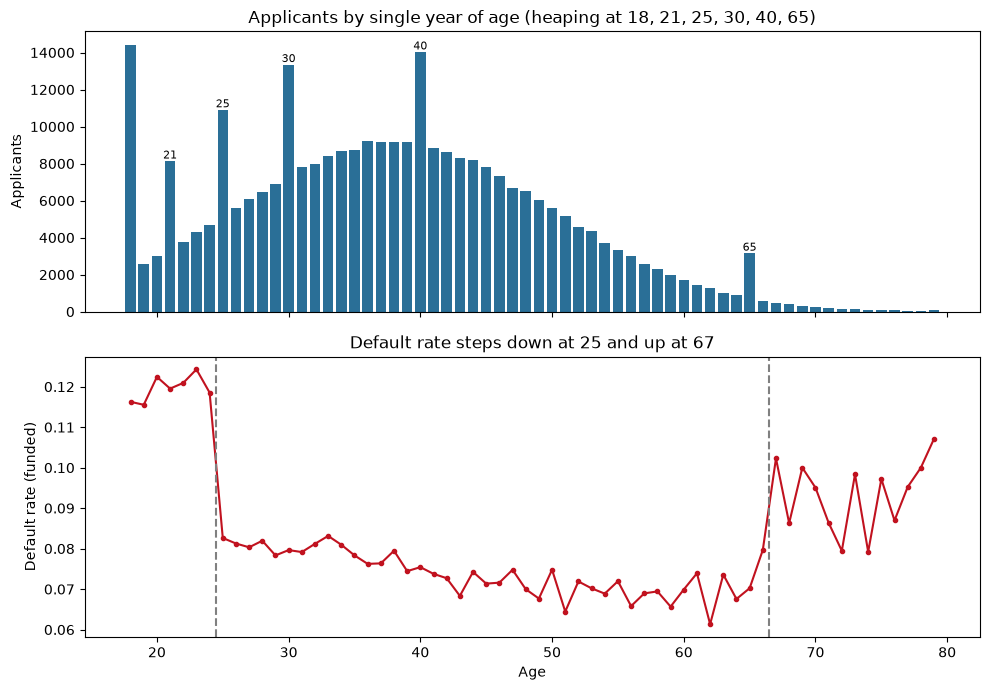

In [4]:
# --------------------------------------------------------------------------------------------
# Q1 Age
# --------------------------------------------------------------------------------------------
section("Q1. AGE")
a = df.groupby("age").size().rename("n").to_frame()
a["neighbor_avg"] = (a.n.shift(1) + a.n.shift(-1)) / 2
a["ratio"] = a.n / a.neighbor_avg
a["n_funded"] = f.groupby("age").size()
a["default"] = f.groupby("age").default_flag.mean()
a["credit"] = df.groupby("age").credit_score.mean()
print(a.round(3).to_string())
print("heaped ages (ratio > 1.4 or endpoints):", a[(a.ratio > 1.4)].index.tolist())
f["age_band"] = pd.cut(f.age, [17, 24, 66, 80], labels=["18-24", "25-66", "67+"])
print(f.groupby("age_band", observed=True).default_flag.agg(["mean", "size"]).round(4))
# step test: logistic with steps vs. smooth quadratic
f["age_lt25"] = (f.age < 25).astype(int); f["age_ge67"] = (f.age >= 67).astype(int)
for fm in ["default_flag ~ age + I(age**2)", "default_flag ~ age_lt25 + age_ge67",
           "default_flag ~ age + I(age**2) + age_lt25 + age_ge67",
           "default_flag ~ credit_score + log_inc + age + I(age**2)",
           "default_flag ~ credit_score + log_inc + age + I(age**2) + age_lt25 + age_ge67"]:
    m = smf.logit(fm, f).fit(disp=0)
    print(f"{fm:80s} LL={m.llf:.1f} AIC={m.aic:.1f}", {k: round(v, 3) for k, v in m.params.items() if "age" in k})
for lo, hi in [(22, 27), (63, 70)]:
    g = f[f.age.between(lo, hi)]
    print(g.groupby("age").default_flag.agg(["mean", "size"]).round(4).T)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].bar(a.index, a.n, color="#2a6f97"); ax[0].set_ylabel("Applicants")
for x in a[(a.ratio > 1.4)].index:
    ax[0].annotate(str(x), (x, a.n[x]), ha="center", va="bottom", fontsize=8)
ax[0].set_title("Applicants by single year of age (heaping at 18, 21, 25, 30, 40, 65)")
ax[1].plot(a.index, a.default, marker="o", ms=3, color="#c1121f")
ax[1].axvline(24.5, ls="--", color="grey"); ax[1].axvline(66.5, ls="--", color="grey")
ax[1].set_ylabel("Default rate (funded)"); ax[1].set_xlabel("Age")
ax[1].set_title("Default rate steps down at 25 and up at 67")
fig.tight_layout(); plt.show()

## Q2. Income

### Q2a. Do risk scores, approvals and defaults differ by income?

**Conclusion: yes, by a lot for the risk score and approvals, and moderately for defaults.** The IRS and approval rate are strongly **U-shaped** in income. Default falls with income up to about $85k, is flat to about $130k, and rises again at the top.

| Income | n | Mean IRS | Approve rate | Default rate (funded) |
|---|---|---|---|---|
| $15–25k | 20,180 | +1.10 | 40% | 10.1% |
| $25–35k | 38,378 | +0.66 | 61% | 9.7% |
| $35–45k | 46,351 | +0.31 | 75% | 8.7% |
| $45–55k | 44,215 | +0.03 | 84% | 8.3% |
| $55–65k | 37,274 | −0.23 | 91% | 7.5% |
| $65–75k | 29,289 | −0.42 | 94% | 7.2% |
| $75–85k | 22,226 | −0.56 | 96% | 6.9% |
| $85–100k | 22,809 | −0.67 | 97% | 7.0% |
| $100–115k | 14,632 | **−0.71** | **97%** | 6.8% |
| $115–130k | 9,067 | −0.65 | 96% | 6.8% |
| $130–145k | 5,614 | −0.46 | 94% | 7.8% |
| $145–160k | 3,416 | −0.17 | 89% | 8.2% |
| $160–175k | 2,217 | +0.21 | 78% | 8.1% |
| $175–200k | 4,332 | **+1.16** | **38%** | 11.4% |

- **IRS:** falls by about 1.8 SD from the lowest incomes to $100–115k, then rises by 1.9 SD to the top bin. Even after controlling for credit score, age and existing-customer status, the score carries a large penalty above about $115k (residual +2.2 SD in the top bin).
- **Approval:** follows the IRS: 40% → 97% → 38%. The highest earners are approved about as often as the lowest.
- **Default:** a much flatter U. It goes from 10.1% at the bottom to 6.8% in the middle, and back to 11.4% in the top bin (among the 68% of top earners who were funded). The data support some upturn at high income, but approvals swing much more than default risk does.


### Q2b. Does income add information beyond credit score? Beyond the IRS?

**Beyond credit score: yes, clearly. Beyond the IRS: statistically detectable but practically negligible.**

Likelihood-ratio tests on the 265,060 funded plans:

| Base model | + income term | LR χ² | df | p |
|---|---|---|---|---|
| credit_score | log income | 200.8 | 1 | 1e-45 |
| credit_score | spline(log income) | 465.6 | 4 | 2e-99 |
| IRS + regime | log income | 7.2 | 1 | 0.007 |
| IRS + regime | spline(log income) | 25.1 | 4 | 5e-5 |

The cross-tabs below show the same thing. Within a credit-score band, default still falls with income. In the 550–600 band, the lowest income quintile defaults at 11.4% and the fourth at 7.1%. Within an IRS quintile (taken within each regime), default barely moves across income quintiles (for example 12.6%, 12.7%, 12.1%, 11.6%, 12.8% in the top IRS quintile). The IRS already uses income, which is consistent with Verizon's description of the model.


Q2. INCOME
                      n    irs  irs_resid  approve  funded   credit  default
inc_bin                                                                     
[15000, 25000)    20180  1.095      0.259    0.403   0.544  588.386    0.101
[25000, 35000)    38378  0.655      0.166    0.607   0.734  596.808    0.097
[35000, 45000)    46351  0.309      0.052    0.750   0.850  602.025    0.087
[45000, 55000)    44215  0.025     -0.062    0.843   0.916  604.922    0.083
[55000, 65000)    37274 -0.231     -0.156    0.906   0.956  608.844    0.075
[65000, 75000)    29289 -0.421     -0.217    0.939   0.975  611.897    0.072
[75000, 85000)    22226 -0.564     -0.249    0.956   0.984  614.576    0.069
[85000, 100000)   22809 -0.670     -0.244    0.966   0.990  616.429    0.070
[100000, 115000)  14632 -0.705     -0.149    0.972   0.992  619.661    0.068
[115000, 130000)   9067 -0.650      0.025    0.963   0.991  622.818    0.068
[130000, 145000)   5614 -0.461      0.302    0.943   0.989  624.

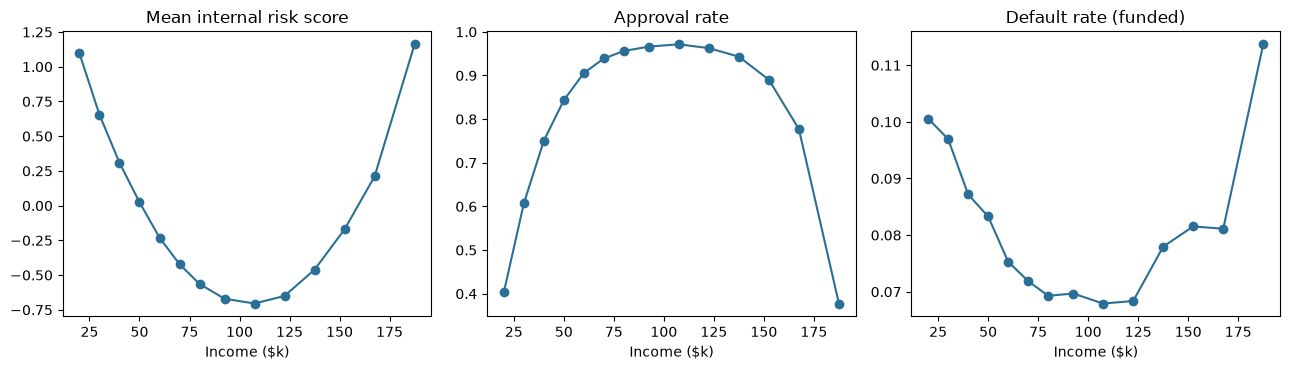

default_flag ~ credit_score + log_inc                                       LR=200.8 df=1 p=1.4e-45


default_flag ~ credit_score + bs(log_inc, df=4)                             LR=465.6 df=4 p=1.82e-99


default_flag ~ internal_risk_score + C(regime) + log_inc                    LR=7.2 df=1 p=0.00733


default_flag ~ internal_risk_score + C(regime) + bs(log_inc, df=4)          LR=25.1 df=4 p=4.74e-05


credit+log_inc coefficients: {'Intercept': 2.1098, 'credit_score': -0.0037, 'log_inc': -0.21}
default by credit band x income quintile:
inc_q          I1     I2     I3     I4     I5
cs_band                                      
(0, 550]    0.148  0.132  0.115  0.102  0.098
(550, 600]  0.114  0.099  0.076  0.071  0.078
(600, 650]  0.089  0.073  0.066  0.063  0.070
(650, 700]  0.069  0.067  0.065  0.063  0.066
(700, 900]  0.068  0.061  0.058  0.059  0.063
default by within-regime IRS quintile x income quintile:
inc_q      I1     I2     I3     I4     I5
irs_qr                                   
1       0.075  0.069  0.064  0.064  0.067
2       0.067  0.065  0.065  0.063  0.062
3       0.065  0.067  0.067  0.064  0.063
4       0.083  0.086  0.075  0.081  0.079
5       0.126  0.127  0.121  0.116  0.128
funded income>=130k: mean IRS -0.080 default 0.0869 | 60-100k: mean IRS -0.534 default 0.0716


In [5]:
# --------------------------------------------------------------------------------------------
# Q2 Income
# --------------------------------------------------------------------------------------------
section("Q2. INCOME")
bins = [15000, 25000, 35000, 45000, 55000, 65000, 75000, 85000, 100000, 115000, 130000, 145000, 160000, 175000, 200001]
df["inc_bin"] = pd.cut(df.income, bins, right=False)
f["inc_bin"] = pd.cut(f.income, bins, right=False)
inc = df.groupby("inc_bin", observed=True).agg(n=("age", "size"), irs=("internal_risk_score", "mean"),
                                                irs_resid=("irs_resid", "mean"), approve=("approve", "mean"),
                                                funded=("funded", "mean"), credit=("credit_score", "mean"))
inc["default"] = f.groupby("inc_bin", observed=True).default_flag.mean()
print(inc.round(3).to_string())
print("corr:", df[["income", "credit_score", "internal_risk_score"]].corr().round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
mid = [(iv.left + iv.right) / 2000 for iv in inc.index]
for a_, col, lab in zip(ax, ["irs", "approve", "default"], ["Mean internal risk score", "Approval rate", "Default rate (funded)"]):
    a_.plot(mid, inc[col], marker="o", color="#2a6f97"); a_.set_xlabel("Income ($k)"); a_.set_title(lab)
fig.tight_layout(); plt.show()

# Q2b: does income add information beyond credit score / beyond IRS? (likelihood-ratio tests, funded plans)
f["log_inc"] = np.log(f.income)
def lr_test(base, full, data):
    m0 = smf.logit(base, data).fit(disp=0); m1 = smf.logit(full, data).fit(disp=0)
    lr = 2 * (m1.llf - m0.llf); k = len(m1.params) - len(m0.params)
    return round(lr, 1), k, stats.chi2.sf(lr, k), m1
for base, full in [("default_flag ~ credit_score", "default_flag ~ credit_score + log_inc"),
                   ("default_flag ~ credit_score", "default_flag ~ credit_score + bs(log_inc, df=4)"),
                   ("default_flag ~ internal_risk_score + C(regime)", "default_flag ~ internal_risk_score + C(regime) + log_inc"),
                   ("default_flag ~ internal_risk_score + C(regime)", "default_flag ~ internal_risk_score + C(regime) + bs(log_inc, df=4)")]:
    lr, k, p, m1 = lr_test(base, full, f)
    print(f"{full:75s} LR={lr} df={k} p={p:.3g}")
m = smf.logit("default_flag ~ credit_score + log_inc", f).fit(disp=0)
print("credit+log_inc coefficients:", m.params.round(4).to_dict())
print("default by credit band x income quintile:")
f["inc_q"] = pd.qcut(f.income, 5, labels=[f"I{i}" for i in range(1, 6)])
print(f.pivot_table(index="cs_band", columns="inc_q", values="default_flag", aggfunc="mean", observed=True).round(3))
print("default by within-regime IRS quintile x income quintile:")
f["irs_qr"] = f.groupby("regime").internal_risk_score.transform(lambda s: pd.qcut(s, 5, labels=False) + 1)
print(f.pivot_table(index="irs_qr", columns="inc_q", values="default_flag", aggfunc="mean", observed=True).round(3))
# high-income mis-scoring: IRS vs default among income > 130k
hi = f[f.income >= 130000]; lo = f[(f.income >= 60000) & (f.income < 100000)]
print("funded income>=130k: mean IRS %.3f default %.4f | 60-100k: mean IRS %.3f default %.4f" %
      (hi.internal_risk_score.mean(), hi.default_flag.mean(), lo.internal_risk_score.mean(), lo.default_flag.mean()))

## Q3. Default flag

### Q3a. Who has no default_flag?

**Conclusion: exactly the 34,940 applicants who were not funded.** No funded plan is missing the flag.

| initial_decision | default_flag missing | observed |
|---|---|---|
| Approve | 0 | 242,673 |
| Conditional | 16,706 (turned down the counteroffer) | 22,387 (accepted it) |
| Deny | 18,234 (all of them) | 0 |

### Q3b. Final regime: not-funded applicants riskier than every funded applicant

**Conclusion: 61.7% (11,195 of 18,131).** The highest IRS among funded plans in R3 is 1.502, which is the R3 deny cut-off. Every denied R3 applicant (IRS 1.502 to 4.358) is above it. Every R3 applicant who turned down a counteroffer (IRS 0.845 to 1.502) is inside the funded range.


### Q3c. Should Verizon trust a funded-plan model's estimates for denied applicants?

**Conclusion: for applicants who were denied, not much. For applicants who turned down a counteroffer, reasonably. And for a large group of R3 denials, the looser R2 regime gives real outcome data.**

- **Denied applicants: low trust.** Every R3 denial is outside the score range the model was trained on. Any estimate for them is pure extrapolation, and the answer depends on the functional form you choose rather than on data. For example, a logistic fit on R3 funded plans already under-predicts the top funded decile (it fits 15%; the actual rate is 17%). Denied applicants may also differ in ways the data do not record. None of these estimates can be checked against outcomes.
- **Applicants who turned down a counteroffer: more trustworthy.** They have the same score and credit profile as those who accepted (mean IRS 1.23 vs 1.16, credit score 547 vs 547), and those who accepted have observed outcomes. The remaining differences are mostly observable (decliners have lower income, $38k vs $58k, and are less often existing customers, 24% vs 34%), so a model can adjust for them. Some unobserved self-selection may remain.
- **R3 denials that R2 would have funded: also more trustworthy.** For the same applicant, the R3 score is 0.53 higher than the R2 score, and R2 funded people up to a deny cut-off of 1.92. After removing each regime's score offset (see Q4a), **86.6% of R3 denials (9,699) fall inside the range R2 actually funded.** R2 outcomes for those people, scaled up for the R3 shock, are evidence rather than extrapolation. The one assumption is that the shock affects these applicants by roughly the same proportion as everyone else; Q4e shows it does, at about 1.5–2.1×.


Q3. DEFAULT FLAG
default_flag      missing  observed     All
initial_decision                           
Approve                 0    242673  242673
Conditional         16706     22387   39093
Deny                18234         0   18234
All                 34940    265060  300000
default_flag                       False  True 
initial_decision final_status                  
Approve          Funded_Original  242673      0
Conditional      Funded_Revised    22387      0
                 Not_Funded            0  16706
Deny             Not_Funded            0  18234


R3 max funded IRS = 1.5019; not-funded n=18131; share above max = 0.6175 (11195)
                    count   mean    std    min    25%    50%    75%    max
initial_decision                                                          
Conditional        6936.0  1.173  0.185  0.845  1.018  1.174  1.330  1.502
Deny              11195.0  1.988  0.411  1.502  1.670  1.888  2.189  4.358
R3 funded IRS describe: {'count': 82149.0, 'mean': -0.007, 'std': 0.768, 'min': -3.476, '25%': -0.519, '50%': 0.054, '75%': 0.567, 'max': 1.502}
                internal_risk_score  credit_score     income  existing_customer  dp_increase  downgrade
final_status                                                                                           
Funded_Revised                1.158       546.510  57572.118               0.34        0.091      0.289
Not_Funded                    1.229       546.753  38113.067               0.24        0.112      0.439


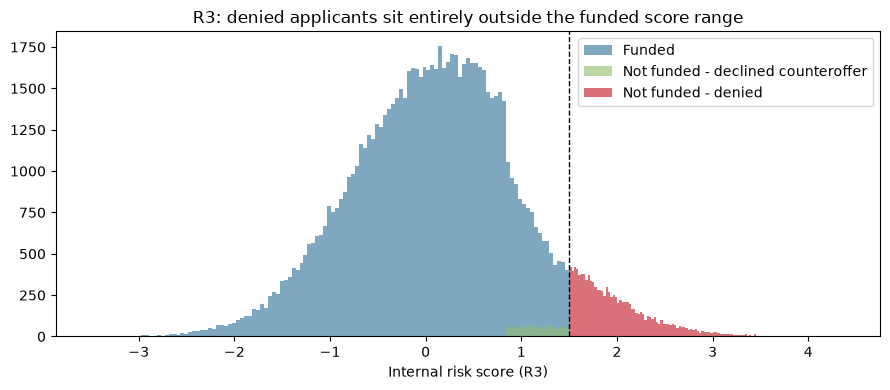

In [6]:
# --------------------------------------------------------------------------------------------
# Q3 Default flag coverage
# --------------------------------------------------------------------------------------------
section("Q3. DEFAULT FLAG")
print(pd.crosstab(df.initial_decision, df.default_flag.isna().map({True: "missing", False: "observed"}), margins=True))
print(pd.crosstab([df.initial_decision, df.final_status], df.default_flag.isna()))
r3 = df[df.regime == "R3"]
mx = r3[r3.funded == 1].internal_risk_score.max()
r3nf = r3[r3.funded == 0]
share = (r3nf.internal_risk_score > mx).mean()
print(f"R3 max funded IRS = {mx:.4f}; not-funded n={len(r3nf)}; share above max = {share:.4f} ({(r3nf.internal_risk_score > mx).sum()})")
print(r3nf.groupby("initial_decision").internal_risk_score.describe().round(3))
print("R3 funded IRS describe:", r3[r3.funded == 1].internal_risk_score.describe().round(3).to_dict())
# overlap: declined counteroffers vs accepted counteroffers
cond = df[df.initial_decision == "Conditional"]
print(cond.groupby("final_status")[["internal_risk_score", "credit_score", "income", "existing_customer", "dp_increase", "downgrade"]].mean().round(3))
fig, ax = plt.subplots(figsize=(9, 4))
for (lab, s), c in zip([("Funded", r3[r3.funded == 1].internal_risk_score),
                        ("Not funded - declined counteroffer", r3[(r3.initial_decision == "Conditional") & (r3.funded == 0)].internal_risk_score),
                        ("Not funded - denied", r3[r3.initial_decision == "Deny"].internal_risk_score)],
                       ["#2a6f97", "#90be6d", "#c1121f"]):
    ax.hist(s, bins=120, alpha=0.6, label=lab, color=c, density=False)
ax.axvline(mx, color="k", ls="--", lw=1); ax.set_xlabel("Internal risk score (R3)"); ax.legend()
ax.set_title("R3: denied applicants sit entirely outside the funded score range")
fig.tight_layout(); plt.show()

## Q4. Structural breaks

### Q4a. Break dates

**Conclusion: break 1 is on 1 August 2023 and break 2 is on 1 May 2024.**

Evidence. I took the IRS minus what applicant characteristics predict (credit score, log income, age, existing customer, device; fitted on R1). A search over every candidate day for the largest 30-day before/after jump picks out exactly these two dates.

| Day | Mean IRS residual | Approve | Deny | Default |
|---|---|---|---|---|
| 2023-07-31 | +0.02 | 82.9% | 6.6% | 7.6% |
| **2023-08-01** | **−0.22** | **91.2%** | **1.3%** | 6.3% |
| 2024-04-30 | −0.25 | 90.3% | 1.1% | 6.6% |
| **2024-05-01** | **+0.31** | **70.6%** | **13.6%** | **10.7%** |

The decision cut-offs, read off the data, also move on exactly those days:

| Regime | Approve if IRS ≤ | Conditional | Deny if IRS > | Score offset for the same applicant (vs R1) |
|---|---|---|---|---|
| R1 | 0.845 | 0.845–1.502 | 1.502 | 0 |
| R2 | 0.960 | 0.960–1.922 | 1.922 | −0.24 |
| R3 | 0.845 | 0.845–1.502 | 1.502 | +0.29 |

The score's slopes on credit score (−0.0115), log income (−0.61) and existing customer (−0.38) are identical in all three regimes. Only the intercept moves.

*The code and output for Q4a are in the Regime determination section near the top.*

### Q4b. Which columns shift, and when?

The test compares 60 days before and 60 days after each break (Welch t-test for numeric columns, χ² for categorical ones).

| Column | Break 1 (Aug 2023) | Break 2 (May 2024) | Verdict |
|---|---|---|---|
| credit_score | 609.4 → 609.3 (p = 0.79) | 608.9 → 609.2 (p = 0.57) | **Neither** |
| age | 37.8 → 37.8 (p = 0.91) | 37.8 → 37.7 (p = 0.54) | **Neither** |
| income | $62.9k → $63.1k (p = 0.58) | $63.0k → $63.1k (p = 0.66) | **Neither** |
| existing_customer | 40.6% → 39.5% (p = 0.01*) | 40.2% → 39.6% (p = 0.19) | **Neither** (*regime means are 39.9%, 40.0%, 40.0%) |
| device_requested | p = 0.15 | p = 0.36 | **Neither** |
| internal_risk_score | −0.03 → −0.26 (p ≈ 1e-158) | −0.27 → +0.27 (p ≈ 0) | **Both** |
| initial_decision | Approve 81% → 90%, Deny 6.1% → 1.6% | Approve 89% → 72%, Deny 1.3% → 10.8% | **Both** |
| default_flag | 6.80% → 6.84% (p = 0.85) | 6.79% → 10.62% (p = 3e-45) | **Second only** |

In [7]:
# --------------------------------------------------------------------------------------------
# 4b. Which columns shift at which break (60-day windows either side; Welch t / chi-square)
# --------------------------------------------------------------------------------------------
section("Q4b. SHIFTS AT EACH BREAK")
cols = ["credit_score", "age", "income", "existing_customer", "device_requested", "internal_risk_score",
        "initial_decision", "default_flag"]
rows = []
for name, b in [("Break1", BREAK1), ("Break2", BREAK2)]:
    pre = df[(df.application_date >= b - pd.Timedelta(days=60)) & (df.application_date < b)]
    post = df[(df.application_date >= b) & (df.application_date < b + pd.Timedelta(days=60))]
    for c in cols:
        if df[c].dtype == object or str(df[c].dtype) in ("str", "string"):
            tab = pd.crosstab(pd.concat([pre, post])[c], np.r_[np.zeros(len(pre)), np.ones(len(post))])
            p = stats.chi2_contingency(tab)[1]
            pre_v = pre[c].value_counts(normalize=True).round(3).to_dict()
            post_v = post[c].value_counts(normalize=True).round(3).to_dict()
        else:
            a, bb = pre[c].dropna(), post[c].dropna()
            p = stats.ttest_ind(a, bb, equal_var=False).pvalue
            pre_v, post_v = round(a.mean(), 4), round(bb.mean(), 4)
        rows.append(dict(brk=name, col=c, pre=pre_v, post=post_v, p=p))
shift = pd.DataFrame(rows)
print(shift.to_string())
print(df.groupby("regime")[["credit_score", "age", "income", "existing_customer", "internal_risk_score",
                            "irs_resid", "approve", "default_flag"]].mean().round(4))
print(pd.crosstab(df.regime, df.initial_decision, normalize="index").round(3))
print(pd.crosstab(df.regime, df.device_requested, normalize="index").round(3))


Q4b. SHIFTS AT EACH BREAK
       brk                  col                                                      pre                                                     post              p
0   Break1         credit_score                                                 609.4365                                                 609.2781   7.877172e-01
1   Break1                  age                                                  37.7973                                                   37.786   9.139278e-01
2   Break1               income                                               62917.9007                                               63087.6812   5.834811e-01
3   Break1    existing_customer                                                   0.4063                                                   0.3951   1.089087e-02
4   Break1     device_requested              {'Mid': 0.399, 'High': 0.304, 'Low': 0.297}                {'Mid': 0.404, 'Low': 0.3, 'High': 0.296}   1.547356e-01
5   Bre

### Q4c. What the pattern means

At **break 1**, only Verizon's own scoring and cut-offs changed (the score fell by 0.24 for the same applicant and the cut-offs loosened). The applicants and their repayment behaviour did not change, so this was a purely internal promotional loosening. At **break 2**, the scoring was tightened again (+0.53), the applicant pool still did not change, and yet defaults jumped about 55%. That combination points to an **external economic shock to repayment** arriving together with Verizon's response to it.

### Q4d. Are defaults seasonal?

**Conclusion: I disagree with the teammate. The "May jump" is the 1 May 2024 regime change, which the pooled calendar months mix in.**

| Month | 2023 | 2024 | Pooled (teammate) |
|---|---|---|---|
| Jan–Apr (average) | 6.96% | 6.65% | 6.80% |
| May–Dec (average) | **6.86%** | **10.69%** | 8.66% |

- In 2023, May–December is *not* higher than January–April (6.9% vs 7.0%). Every 2023 month is between 6.6% and 7.2%.
- In 2024, the jump happens exactly on 1 May and stays flat afterwards (10.2% to 11.2% each month). That is the R3 shock, not a season.
- Within each regime, month does not predict default (χ² p = 0.53, 0.62 and 0.41 for R1, R2 and R3). Month dummies add nothing after controlling for regime (LR χ² = 7.4, df = 11, p = 0.77).
- There *is* one real seasonal pattern, and it is in the applicants: average credit score drops about 10 points in November and December both years (609 → 599). Even so, holiday defaults are not elevated.

"Tighten every summer and fall" would cut profitable volume in response to a pattern that is not there.


Q4d. SEASONALITY
year     2023    2024  pooled
month                        
1      0.0689  0.0682  0.0685
2      0.0720  0.0626  0.0671
3      0.0688  0.0670  0.0679
4      0.0690  0.0678  0.0684
5      0.0721  0.1058  0.0882
6      0.0655  0.1069  0.0855
7      0.0703  0.1043  0.0868
8      0.0698  0.1074  0.0873
9      0.0666  0.1118  0.0876
10     0.0690  0.1069  0.0866
11     0.0672  0.1017  0.0832
12     0.0684  0.1100  0.0878
pooled Jan-Apr vs May-Dec: 0.068 0.0866
2023 Jan-Apr 0.0696 May-Dec 0.0686


2024 Jan-Apr 0.0665 May-Dec 0.1069
by regime x month:
regime      R1      R2      R3
month                         
1       0.0689  0.0682     NaN
2       0.0720  0.0626     NaN
3       0.0688  0.0670     NaN
4       0.0690  0.0678     NaN
5       0.0721     NaN  0.1058
6       0.0655     NaN  0.1069
7       0.0703     NaN  0.1043
8          NaN  0.0698  0.1074
9          NaN  0.0666  0.1118
10         NaN  0.0690  0.1069
11         NaN  0.0672  0.1017
12         NaN  0.0684  0.1100
R1 chi2 p-value month vs default: 0.525
R2 chi2 p-value month vs default: 0.6212
R3 chi2 p-value month vs default: 0.408


LR test month dummies given regime: chi2=7.4 df=11 p=0.765
credit score by month and year (applicant mix):
year    2023   2024
month              
1      609.8  609.1
2      608.9  609.0
3      609.3  608.9
4      609.2  608.9
5      609.9  608.4
6      609.6  610.0
7      609.4  608.3
8      608.5  608.2
9      609.9  609.2
10     609.2  607.9
11     599.5  598.9
12     598.3  599.6


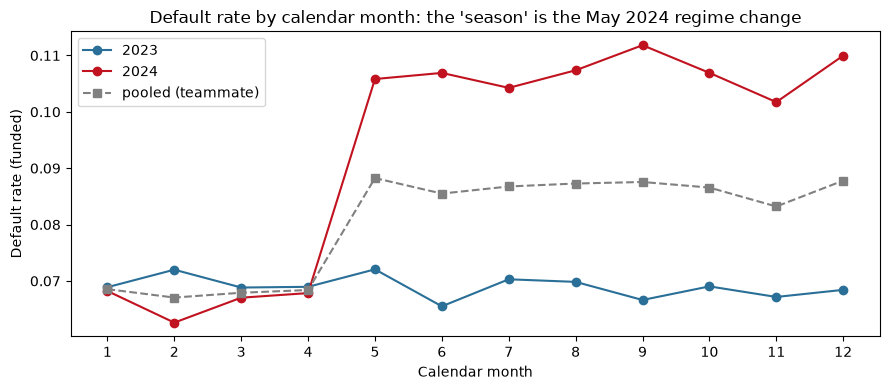

In [8]:
# --------------------------------------------------------------------------------------------
# 4d. Seasonality
# --------------------------------------------------------------------------------------------
section("Q4d. SEASONALITY")
mon = f.pivot_table(index="month", columns="year", values="default_flag", aggfunc="mean")
mon["pooled"] = f.groupby("month").default_flag.mean()
print(mon.round(4))
print("pooled Jan-Apr vs May-Dec:", f[f.month <= 4].default_flag.mean().round(4), f[f.month >= 5].default_flag.mean().round(4))
for y in [2023, 2024]:
    g = f[f.year == y]
    print(y, "Jan-Apr", g[g.month <= 4].default_flag.mean().round(4), "May-Dec", g[g.month >= 5].default_flag.mean().round(4))
print("by regime x month:")
print(f.pivot_table(index="month", columns="regime", values="default_flag", aggfunc="mean").round(4))
# within-regime month effect test (R2 spans Aug-Apr, R3 May-Dec, so test month within R2 and R3 separately)
for r in ["R1", "R2", "R3"]:
    g = f[f.regime == r]
    tab = pd.crosstab(g.month, g.default_flag)
    print(r, "chi2 p-value month vs default:", round(stats.chi2_contingency(tab)[1], 4))
m_season = smf.logit("default_flag ~ C(regime) + C(month)", f).fit(disp=0)
m_noseason = smf.logit("default_flag ~ C(regime)", f).fit(disp=0)
lr = 2 * (m_season.llf - m_noseason.llf)
print("LR test month dummies given regime: chi2=%.1f df=11 p=%.3f" % (lr, stats.chi2.sf(lr, 11)))
print("credit score by month and year (applicant mix):")
print(df.pivot_table(index="month", columns="year", values="credit_score", aggfunc="mean").round(1))

fig, ax = plt.subplots(figsize=(9, 4))
for y, c in [(2023, "#2a6f97"), (2024, "#c1121f")]:
    ax.plot(mon.index, mon[y], marker="o", color=c, label=str(y))
ax.plot(mon.index, mon["pooled"], marker="s", color="grey", ls="--", label="pooled (teammate)")
ax.set_xticks(range(1, 13)); ax.set_xlabel("Calendar month"); ax.set_ylabel("Default rate (funded)")
ax.legend(); ax.set_title("Default rate by calendar month: the 'season' is the May 2024 regime change")
fig.tight_layout(); plt.show()

### Q4e. Did the tightening backfire?

**Conclusion: I disagree with the teammate. Defaults rose by 3–4 points in *every* risk band, so the economy made things worse. The tightening slightly lowered the funded default rate.**

Default rate by IRS quintile (pooled cut-points, funded plans):

| IRS quintile | R1 | R2 | R3 |
|---|---|---|---|
| Q1 (safest) | 5.6% | 5.6% | 8.8% |
| Q2 | 5.2% | 5.4% | 8.4% |
| Q3 | 5.5% | 5.4% | 8.9% |
| Q4 | 7.3% | 7.2% | 10.2% |
| Q5 (riskiest) | 11.5% | 11.7% | 14.9% |

- Within every band, R3 defaults are 3–4 points higher. The same holds on a score that is fixed across regimes (characteristics only) and within credit-score bands (for example, 700+ goes from 5.1% in R2 to 8.2% in R3). This is a shock that hits everyone, not a selection effect.
- Because the R3 score is shifted up, an R3 applicant in a given IRS band is actually *safer* than an R1/R2 applicant in the same band. The raw comparison therefore *understates* the shock.
- **The counterfactual:** with R2's funded risk mix and R3's within-band default rates, the R3 default rate would have been **11.2%**, not 10.7%. Tightening reduced defaults by about 0.5 points.
- There is a real criticism of the tightening, but it is about profit, not defaults. The applicants it removed would default at about 16–25% (Q8), well below the 41.7% break-even, so tightening gave up profitable business.


Q4e. DEFAULT BY IRS QUINTILE AND REGIME
funded default by regime: {'R1': 0.0695, 'R2': 0.0675, 'R3': 0.1069}
regime      R1      R2      R3
irs_q                         
Q1      0.0561  0.0557  0.0879
Q2      0.0524  0.0540  0.0844
Q3      0.0551  0.0536  0.0885
Q4      0.0729  0.0718  0.1022
Q5      0.1146  0.1170  0.1488
regime     R1     R2     R3
irs_q                      
Q1      15591  27170  10251
Q2      15966  22880  14166
Q3      15913  20297  16802
Q4      15589  18201  19222
Q5      14565  16739  21708


regime      R1      R2      R3
fix_q                         
Q1      0.0596  0.0568  0.0895
Q2      0.0543  0.0561  0.0908
Q3      0.0570  0.0568  0.0972
Q4      0.0718  0.0628  0.1165
Q5      0.1069  0.0968  0.1527
regime     R1     R2     R3
irs_q                      
Q1      0.201  0.258  0.125
Q2      0.206  0.217  0.172
Q3      0.205  0.193  0.205
Q4      0.201  0.173  0.234
Q5      0.188  0.159  0.264
R3 default if R3 had R2's funded risk mix: 0.1117
regime          R1      R2      R3
cs_band                           
(0, 550]    0.1069  0.1030  0.1538
(550, 600]  0.0789  0.0712  0.1197
(600, 650]  0.0613  0.0587  0.0995
(650, 700]  0.0555  0.0541  0.0898
(700, 900]  0.0532  0.0510  0.0822


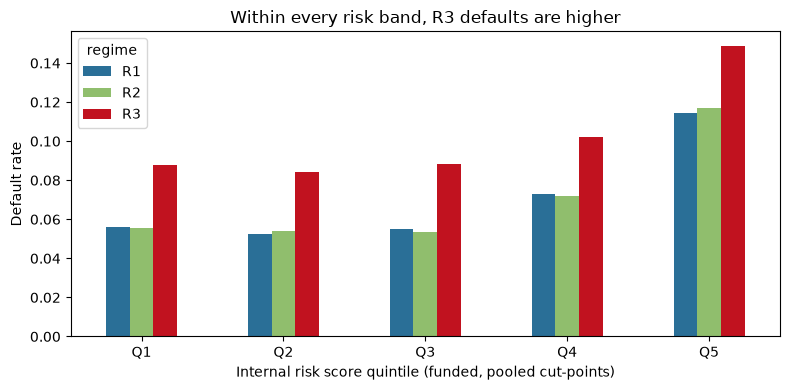

In [9]:
# --------------------------------------------------------------------------------------------
# 4e. Tightening backfire?
# --------------------------------------------------------------------------------------------
section("Q4e. DEFAULT BY IRS QUINTILE AND REGIME")
print("funded default by regime:", f.groupby("regime").default_flag.mean().round(4).to_dict())
f["irs_q"] = pd.qcut(f.internal_risk_score, 5, labels=[f"Q{i}" for i in range(1, 6)])
t = f.pivot_table(index="irs_q", columns="regime", values="default_flag", aggfunc="mean", observed=True)
t_n = f.pivot_table(index="irs_q", columns="regime", values="default_flag", aggfunc="size", observed=True)
print(t.round(4)); print(t_n)
# same comparison on a regime-invariant score (applicant characteristics only, R1 formula)
f["irs_fixed"] = irs_fit.predict(f)
f["fix_q"] = pd.qcut(f.irs_fixed, 5, labels=[f"Q{i}" for i in range(1, 6)])
print(f.pivot_table(index="fix_q", columns="regime", values="default_flag", aggfunc="mean", observed=True).round(4))
# composition: share of funded in each quintile by regime
print(pd.crosstab(f.irs_q, f.regime, normalize="columns").round(3))
# what default rate would R3 have with R3 within-band rates but R2's funded mix?
mix_r2 = pd.crosstab(f.fix_q, f.regime, normalize="columns")["R2"]
rate_r3 = f[f.regime == "R3"].groupby("fix_q", observed=True).default_flag.mean()
print("R3 default if R3 had R2's funded risk mix:", round((mix_r2 * rate_r3).sum(), 4))
# shock shown on credit score bands as well
print(f.pivot_table(index="cs_band", columns="regime", values="default_flag", aggfunc="mean", observed=True).round(4))

fig, ax = plt.subplots(figsize=(8, 4))
t.plot(kind="bar", ax=ax, color=["#2a6f97", "#90be6d", "#c1121f"])
ax.set_ylabel("Default rate"); ax.set_xlabel("Internal risk score quintile (funded, pooled cut-points)")
ax.set_title("Within every risk band, R3 defaults are higher"); plt.xticks(rotation=0)
fig.tight_layout(); plt.show()

## Q5. Internal risk score vs a naive credit-score model

**Conclusion: the IRS is better overall (holdout AUC 0.590 vs 0.563, difference 95% CI [0.022, 0.032]). I found no subgroup where the credit-score model is meaningfully better.**

Setup: logistic regressions on funded plans, a 70/30 train/holdout split stratified by regime and default (185,542 / 79,518), and all metrics computed on the holdout.

| Model | AUC | Log-loss | Brier |
|---|---|---|---|
| credit_score only | 0.563 | 0.2777 | 0.0735 |
| internal_risk_score only | **0.590** | **0.2760** | **0.0732** |

**Metric: AUC (ROC area).** The approval decision ranks applicants and cuts the list at a threshold, and AUC measures exactly that: the probability that a randomly chosen defaulter is ranked riskier than a randomly chosen non-defaulter. It does not depend on where Verizon sets the cut-off. It is also not distorted by the R3 jump in the base rate, which would make accuracy-type metrics misleading. Because the break-even decision in Q8 needs probabilities, I report log-loss and Brier score as calibration checks alongside it.

**Subgroups** (holdout AUC, credit score / IRS):

| Subgroup | Credit score | IRS | Comment |
|---|---|---|---|
| R1 / R2 / R3 | 0.573 / 0.573 / 0.557 | 0.585 / 0.583 / 0.572 | IRS better in every regime |
| New / existing customers | 0.568 / 0.554 | 0.613 / 0.576 | IRS better |
| Credit score ≤ 550 | 0.536 | 0.595 | IRS much better |
| Credit score > 650 | 0.495–0.497 | 0.514–0.526 | Both close to random |
| Income $100–130k | **0.545** | **0.537** | Only subgroup where credit score wins, but the CI of the difference is [−0.020, +0.004], so it is a tie |
| Income ≥ $130k | 0.547 | 0.592 | IRS better: it captures the high-income upturn |

Two caveats about the IRS:

- When fitted on all regimes together, both single-score models are mis-calibrated in R3. They predict 8.6% (IRS) and 7.9% (credit score) against an actual 10.7%, because neither knows about the shock.
- In R3, the bottom six IRS deciles all default at 8.2–9.4%. The IRS does not distinguish among lower-risk applicants.

In [10]:
# --------------------------------------------------------------------------------------------
# Q5 / Q6 Models (funded plans, 70/30 stratified holdout)
# --------------------------------------------------------------------------------------------
section("Q5. CREDIT SCORE vs INTERNAL RISK SCORE")
train, test = train_test_split(f, test_size=0.3, random_state=42, stratify=f.regime + f.default_flag.astype(str))
train, test = train.copy(), test.copy()
print("train", train.shape, "test", test.shape, "test default rate", test.default_flag.mean().round(4))

def evaluate(name, p, data=test):
    return dict(model=name, AUC=roc_auc_score(data.default_flag, p), logloss=log_loss(data.default_flag, p),
                Brier=brier_score_loss(data.default_flag, p))

m_cs = smf.logit("default_flag ~ credit_score", train).fit(disp=0)
m_irs = smf.logit("default_flag ~ internal_risk_score", train).fit(disp=0)
test["p_cs"] = m_cs.predict(test); test["p_irs"] = m_irs.predict(test)
res = [evaluate("credit_score only", test.p_cs), evaluate("internal_risk_score only", test.p_irs)]
print(pd.DataFrame(res).round(4))

def sub_auc(data, by):
    out = []
    for k, g in data.groupby(by, observed=True):
        if g.default_flag.nunique() < 2:
            continue
        out.append(dict(group=f"{by}={k}", n=len(g), dflt=g.default_flag.mean(),
                        AUC_cs=roc_auc_score(g.default_flag, g.p_cs), AUC_irs=roc_auc_score(g.default_flag, g.p_irs)))
    return out
test["age_band"] = pd.cut(test.age, [17, 24, 66, 80], labels=["18-24", "25-66", "67+"])
test["inc_band"] = pd.cut(test.income, [0, 35000, 60000, 100000, 130000, 300000])
test["cs_band"] = pd.cut(test.credit_score, [0, 550, 600, 650, 700, 900])
rows = []
for by in ["regime", "existing_customer", "final_status", "device_final", "age_band", "inc_band", "cs_band"]:
    rows += sub_auc(test, by)
sub = pd.DataFrame(rows); sub["irs_minus_cs"] = sub.AUC_irs - sub.AUC_cs
print(sub.round(4).to_string())
# bootstrap CI for high-income subgroup difference
rng = np.random.default_rng(0)
for lab, g in [("income 100-130k", test[(test.income > 100000) & (test.income <= 130000)]), ("credit>650", test[test.credit_score > 650]), ("income>=130k", test[test.income >= 130000]), ("all", test)]:
    diffs = []
    for _ in range(300):
        s = g.sample(len(g), replace=True, random_state=rng.integers(1e9))
        diffs.append(roc_auc_score(s.default_flag, s.p_irs) - roc_auc_score(s.default_flag, s.p_cs))
    print(lab, "AUC(irs)-AUC(cs) 95% CI:", np.percentile(diffs, [2.5, 97.5]).round(4))
# calibration of IRS-only model in R3
print("mean predicted vs actual by regime (IRS model):")
print(test.groupby("regime")[["p_irs", "p_cs", "default_flag"]].mean().round(4))


Q5. CREDIT SCORE vs INTERNAL RISK SCORE


train (185542, 37) test (79518, 37) test default rate 0.0803


                      model     AUC  logloss   Brier
0         credit_score only  0.5626   0.2777  0.0735
1  internal_risk_score only  0.5895   0.2760  0.0732


                           group      n    dflt  AUC_cs  AUC_irs  irs_minus_cs
0                      regime=R1  23287  0.0695  0.5734   0.5848        0.0115
1                      regime=R2  31587  0.0675  0.5727   0.5832        0.0105
2                      regime=R3  24644  0.1068  0.5566   0.5722        0.0156
3            existing_customer=0  46035  0.0731  0.5677   0.6125        0.0448
4            existing_customer=1  33483  0.0902  0.5540   0.5763        0.0223
5   final_status=Funded_Original  72828  0.0738  0.5399   0.5628        0.0229
6    final_status=Funded_Revised   6690  0.1510  0.5118   0.5400        0.0282
7              device_final=High  22961  0.0787  0.5513   0.5793        0.0280
8               device_final=Low  24888  0.0837  0.5702   0.5989        0.0287
9               device_final=Mid  31669  0.0786  0.5635   0.5886        0.0251
10                age_band=18-24   8947  0.1213  0.5540   0.5743        0.0203
11                age_band=25-66  69868  0.0749  0.5

income 100-130k AUC(irs)-AUC(cs) 95% CI: [-0.0199  0.0042]


credit>650 AUC(irs)-AUC(cs) 95% CI: [0.0076 0.0346]


income>=130k AUC(irs)-AUC(cs) 95% CI: [0.0209 0.0709]


all AUC(irs)-AUC(cs) 95% CI: [0.0216 0.0319]
mean predicted vs actual by regime (IRS model):
         p_irs    p_cs  default_flag
regime                              
R1      0.0794  0.0795        0.0695
R2      0.0764  0.0816        0.0675
R3      0.0856  0.0789        0.1068


## Q6. A better default model

**Conclusion: a logistic model with credit-score and income splines, two age steps, an existing-customer flag and regime dummies reaches a holdout AUC of 0.620.** That is about +0.03 over the IRS and +0.06 over credit score, with bootstrap CIs that exclude zero. It is also well calibrated.

| Model (same holdout) | AUC | Log-loss | Brier |
|---|---|---|---|
| credit_score only | 0.563 | 0.2777 | 0.0735 |
| IRS only | 0.590 | 0.2760 | 0.0732 |
| IRS + regime dummies | 0.603 | 0.2747 | 0.0730 |
| Linear logit, raw features, no feature engineering | 0.605 | 0.2745 | 0.0730 |
| **New model: spline/step logistic** | **0.620** | **0.2728** | **0.0728** |
| New model + IRS | 0.621 | 0.2726 | 0.0727 |
| Gradient boosting, same raw inputs | 0.621 | 0.2726 | 0.0728 |

Bootstrap 95% CIs of the AUC gain for the new model: vs credit score [0.050, 0.064]; vs IRS [0.024, 0.038]; vs IRS + regime [0.013, 0.021].

**Functional form:**

logit P(default) = β₀ + s₁(credit_score) + s₂(log income) + β₁·1[age < 25] + β₂·1[age ≥ 67] + β₃·existing_customer + β₄·R2 + β₅·R3

Here s₁ and s₂ are B-splines with 5 degrees of freedom.

| Term | Coefficient (log-odds) | Odds ratio | Engineering reason |
|---|---|---|---|
| age < 25 | +0.356 | 1.43 | Step found in Q1. Replaces a linear age term, whose coefficient is about 0 once the steps are included |
| age ≥ 67 | +0.391 | 1.48 | Step found in Q1 |
| existing_customer | +0.202 | 1.22 | Existing customers default *more*, but the IRS gives them a bonus |
| R3 | +0.502 | 1.65 | Shock in the final regime (Q4); use R3 for current scoring |
| R2 | −0.083 | 0.92 | |
| spline(log income) | U-shape | | Default falls with income, then rises above about $130k (Q2) |
| spline(credit_score) | Falls, then flattens above about 650 | | Credit score stops helping above about 650 |

**What I tried and dropped:**

- `down_payment_base` is an exact function of credit score.
- `down_payment_final` and `downgrade` are outcomes of the negotiation and do not predict default once risk is controlled for (Q7).
- Device tier is not significant.
- Gradient boosting matches but does not beat the logistic model, which suggests the engineered terms capture the structure.
- Adding the IRS gains only +0.001. Everything the IRS knows is already in these inputs.

**Calibration.** The average predicted default by regime is 6.93% / 6.73% / 10.67%, against actual rates of 6.95% / 6.75% / 10.68%. By predicted decile, predictions run from 4.3% to 15.0%, against actual rates of 4.5% to 14.8%.

**Caveat.** Within R3 alone, the gain over the IRS is smaller (AUC 0.578 vs 0.572). A model fitted only on R3 reaches 0.579, so the attainable ranking power in the shock regime appears to be lower. The pooled gain comes partly from the steps and splines (R1/R2: about +0.02 to +0.03) and partly from the regime adjustment.

**Why the metric matters to Verizon specifically.** Verizon has to sort applicants into approve, counteroffer and deny at in-store speed. The quality of that sorting is the ranking AUC measures. The 41.7% break-even (Q8) turns the decision into a question of probabilities, so calibration (log-loss) matters too: a well-ranked but mis-calibrated score would put the cut-off in the wrong place. For example, both single-score models under-predict R3 by 2–3 points. The new model is better on both counts.

In [11]:
section("Q6. IMPROVED MODEL")
# down_payment_base is an exact linear function of credit score (checked here), so it adds nothing
chk = smf.ols("down_payment_base ~ credit_score", df).fit()
print("down_payment_base = %.4f %+.6f*credit_score, R2=%.6f" % (chk.params.iloc[0], chk.params.iloc[1], chk.rsquared))

def add_features(d):
    d = d.copy()
    d["age_lt25"] = (d.age < 25).astype(int)
    d["age_ge67"] = (d.age >= 67).astype(int)
    d["R3"] = (d.regime == "R3").astype(int)
    d["R2"] = (d.regime == "R2").astype(int)
    return d
train, test = add_features(train), add_features(test)
CS = "bs(credit_score, df=5, lower_bound=300, upper_bound=851)"
LI = "bs(log_inc, df=5, lower_bound=9.6, upper_bound=12.3)"
form_logit = f"default_flag ~ {CS} + {LI} + age_lt25 + age_ge67 + existing_customer + R2 + R3"
m_new = smf.logit(form_logit, train).fit(disp=0, maxiter=200)
test["p_new"] = m_new.predict(test)
m_new2 = smf.logit(form_logit + " + internal_risk_score", train).fit(disp=0, maxiter=200)
test["p_new2"] = m_new2.predict(test)
m_lin = smf.logit("default_flag ~ credit_score + log_inc + age + existing_customer + R2 + R3", train).fit(disp=0)
test["p_lin"] = m_lin.predict(test)
m_irs_reg = smf.logit("default_flag ~ internal_risk_score + R2 + R3", train).fit(disp=0)
test["p_irs_reg"] = m_irs_reg.predict(test)
feats = ["credit_score", "income", "age", "existing_customer", "R2", "R3"]
gbm = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200,
                                     l2_regularization=1.0, random_state=0, early_stopping=True,
                                     validation_fraction=0.15)
gbm.fit(train[feats], train.default_flag)
test["p_gbm"] = gbm.predict_proba(test[feats])[:, 1]
res6 = res + [evaluate("IRS + regime dummies", test.p_irs_reg),
              evaluate("Linear logit, raw features (no engineering)", test.p_lin),
              evaluate("NEW: spline/step logistic", test.p_new),
              evaluate("NEW + IRS", test.p_new2),
              evaluate("Gradient boosting (same raw features)", test.p_gbm)]
res6 = pd.DataFrame(res6); print(res6.round(4).to_string())
print(m_new.summary2().tables[1].round(4).to_string())
for lab, col in [("cs", "p_cs"), ("irs", "p_irs"), ("irs_reg", "p_irs_reg")]:
    diffs = []
    for _ in range(300):
        s = test.sample(len(test), replace=True, random_state=rng.integers(1e9))
        diffs.append(roc_auc_score(s.default_flag, s.p_new) - roc_auc_score(s.default_flag, s[col]))
    print(f"AUC(new)-AUC({lab}) 95% CI:", np.percentile(diffs, [2.5, 97.5]).round(4))
print("AUC within each regime (cs / irs / new):")
for r, g in test.groupby("regime"):
    print(r, round(roc_auc_score(g.default_flag, g.p_cs), 4), round(roc_auc_score(g.default_flag, g.p_irs), 4),
          round(roc_auc_score(g.default_flag, g.p_new), 4))
tr3, te3 = train[train.regime == "R3"], test[test.regime == "R3"]
m_r3 = smf.logit(f"default_flag ~ {CS} + {LI} + age_lt25 + age_ge67 + existing_customer", tr3).fit(disp=0, maxiter=200)
print("R3-only fit, R3 holdout AUC:", round(roc_auc_score(te3.default_flag, m_r3.predict(te3)), 4))
print("calibration by regime (new model):")
print(test.groupby("regime")[["p_new", "default_flag"]].mean().round(4))
test["p_new_dec"] = pd.qcut(test.p_new, 10, labels=False)
print(test.groupby("p_new_dec")[["p_new", "default_flag"]].mean().round(4).T)
# business view: among the riskiest 10% / 20% flagged by each model, what share of defaults & losses captured
for col in ["p_cs", "p_irs", "p_new"]:
    for q in [0.1, 0.2]:
        cut = test[col].quantile(1 - q); fl = test[test[col] >= cut]
        print(col, f"top {int(q*100)}%: captures {fl.default_flag.sum() / test.default_flag.sum():.3f} of defaults, "
              f"{fl[fl.default_flag == 1].profit.sum() / test[test.default_flag == 1].profit.sum():.3f} of losses, default rate {fl.default_flag.mean():.3f}")


Q6. IMPROVED MODEL
down_payment_base = 0.2050 -0.000150*credit_score, R2=1.000000


                                         model     AUC  logloss   Brier
0                            credit_score only  0.5626   0.2777  0.0735
1                     internal_risk_score only  0.5895   0.2760  0.0732
2                         IRS + regime dummies  0.6033   0.2747  0.0730
3  Linear logit, raw features (no engineering)  0.6045   0.2745  0.0730
4                    NEW: spline/step logistic  0.6200   0.2728  0.0728
5                                    NEW + IRS  0.6213   0.2726  0.0727
6        Gradient boosting (same raw features)  0.6208   0.2726  0.0728


                                                              Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept                                                   -1.4219    1.3025  -1.0917  0.2750 -3.9748  1.1309
bs(credit_score, df=5, lower_bound=300, upper_bound=851)[0]  0.7403    1.5601   0.4746  0.6351 -2.3173  3.7980
bs(credit_score, df=5, lower_bound=300, upper_bound=851)[1] -0.7673    1.2506  -0.6136  0.5395 -3.2185  1.6839
bs(credit_score, df=5, lower_bound=300, upper_bound=851)[2] -1.2990    1.3300  -0.9767  0.3287 -3.9057  1.3077
bs(credit_score, df=5, lower_bound=300, upper_bound=851)[3] -1.4596    1.2572  -1.1610  0.2456 -3.9237  1.0044
bs(credit_score, df=5, lower_bound=300, upper_bound=851)[4] -0.8312    1.3792  -0.6027  0.5467 -3.5343  1.8720
bs(log_inc, df=5, lower_bound=9.6, upper_bound=12.3)[0]      0.0853    0.1567   0.5447  0.5860 -0.2218  0.3924
bs(log_inc, df=5, lower_bound=9.6, upper_bound=12.3)[1]     -0.2057    0.0915  -2.2475  0.0246 -0.3850 -0.0263
b

AUC(new)-AUC(cs) 95% CI: [0.0504 0.0637]


AUC(new)-AUC(irs) 95% CI: [0.0243 0.0377]


AUC(new)-AUC(irs_reg) 95% CI: [0.0129 0.0209]
AUC within each regime (cs / irs / new):
R1 0.5734 0.5848 0.6051
R2 0.5727 0.5832 0.6087
R3 0.5566 0.5722 0.5783
R3-only fit, R3 holdout AUC: 0.5788
calibration by regime (new model):
         p_new  default_flag
regime                      
R1      0.0693        0.0695
R2      0.0673        0.0675
R3      0.1067        0.1068


p_new_dec          0       1       2       3       4       5       6       7       8       9
p_new         0.0425  0.0498  0.0560  0.0625  0.0695  0.0771  0.0857  0.0964  0.1117  0.1498
default_flag  0.0453  0.0487  0.0504  0.0587  0.0704  0.0763  0.0884  0.0990  0.1176  0.1478
p_cs top 10%: captures 0.157 of defaults, 0.148 of losses, default rate 0.124
p_cs top 20%: captures 0.281 of defaults, 0.268 of losses, default rate 0.112
p_irs top 10%: captures 0.183 of defaults, 0.160 of losses, default rate 0.147
p_irs top 20%: captures 0.323 of defaults, 0.306 of losses, default rate 0.130
p_new top 10%: captures 0.184 of defaults, 0.172 of losses, default rate 0.148
p_new top 20%: captures 0.331 of defaults, 0.317 of losses, default rate 0.133


## Q7. Insight: do counteroffers (downgrades or larger down payments) help or hurt?

**Question.** When the IRS lands in the "Conditional" band, Verizon offers a cheaper device or a larger down payment instead of the plan the applicant asked for. Does that offer lower default enough to be worth the customers and revenue it costs?

**Why this analysis answers it.** A counteroffer can only pay off if it lowers default, because Verizon's profit estimate is ±share of price regardless of down payment. I test this in three ways that complement each other:

1. Among accepted counteroffers, regress default on how large the down-payment increase was and whether there was a downgrade, controlling for IRS, regime and existing-customer status.
2. A regression discontinuity at the Approve/Conditional cut-off. Applicants just below the cut-off get their requested terms; those just above get a counteroffer. If counteroffers reduce risk, default should *drop* just above the line.
3. Model acceptance of the counteroffer to measure what it costs in lost customers.

**Findings.**

| | Effect | Evidence |
|---|---|---|
| Down-payment increase → default | **None** | coefficient +0.15 per unit share (p = 0.78) |
| Downgrade → default | **None** | −0.06 (p = 0.18) |
| Default jump at the Approve/Conditional cut-off | **None** | R3: 14.5% just below vs 14.2% just above (±0.1); log-odds jump −0.17 (p = 0.26); not significant in any regime or bandwidth |
| Downgrade → acceptance | **−0.55 log-odds** (p < 1e-70) | R3 acceptance: 65% for down-payment-only offers vs 50% for downgrades |
| +10 pp down payment → acceptance | **−0.24 log-odds** (p < 1e-15) | Acceptance falls from 68% (smallest increases) to 47% (largest) |

So counteroffers do not reduce default. What they do is (a) push 35–50% of conditional applicants to walk away, and (b) shrink the revenue on downgraded plans. Accepted downgrades earn an average of $85, against $111 for down-payment-only offers in R3.

**Quantified impact (R3, 17,483 conditional applicants in 8 months).** I priced the alternative of approving every conditional applicant on the device and terms they asked for. Each applicant's default probability comes from a logit on accepted counteroffers (IRS + regime + existing customer), which is valid because the terms of the counteroffer do not change default. Expected profit per plan is price × (0.25 − 0.60p).

| Regime | Conditional applicants | Turned down offer | Expected profit, status quo | Expected profit, requested terms | **Gain** |
|---|---|---|---|---|---|
| R1 | 10,824 | 4,497 | $0.75M | $1.46M | +$0.71M |
| R2 | 10,786 | 5,273 | $0.57M | $1.38M | +$0.82M |
| **R3** | **17,483** | **6,936** | **$1.10M** | **$2.12M** | **+$1.01M** (+8.4% of R3 profit) |

The highest predicted default among R3 conditional applicants is 22%, so every one of them is profitable at the 41.7% break-even. The result holds even if a down payment *did* reduce losses one for one. The average increase is 7.4% of price, so with p ≈ 0.165 it would save about 1.2% of price per plan in expected losses, while each lost customer gives up about 15% of price in expected profit.

**Business change.** Replace the Conditional band with a straight approval. If Verizon wants a risk lever, use one that does not cost customers, such as autopay or a deposit that is refunded on completion, and test it before rolling it out.

In [12]:
# --------------------------------------------------------------------------------------------
# Q7 Counteroffers (downgrades / larger down payments)
# --------------------------------------------------------------------------------------------
section("Q7. COUNTEROFFERS")
cond = df[df.initial_decision == "Conditional"].copy()
cond["accepted"] = (cond.final_status == "Funded_Revised").astype(int)
cond["type"] = np.where(cond.downgrade == 1, "downgrade (+dp)", "down payment only")
print(cond.groupby(["regime", "type"]).agg(n=("age", "size"), accept=("accepted", "mean"), dp_inc=("dp_increase", "mean"),
                                            irs=("internal_risk_score", "mean")).round(3))
fr = cond[cond.accepted == 1]
print(fr.groupby(["regime", "type"]).agg(n=("age", "size"), default=("default_flag", "mean"), profit=("profit", "mean")).round(3))
m_def = smf.logit("default_flag ~ internal_risk_score + C(regime) + downgrade + dp_increase + existing_customer", fr).fit(disp=0)
print("default among accepted counteroffers:\n", m_def.summary2().tables[1].round(4))
m_acc = smf.logit("accepted ~ internal_risk_score + C(regime) + downgrade + dp_increase + existing_customer + log_inc + C(device_requested)", cond).fit(disp=0)
print("acceptance of counteroffer:\n", m_acc.summary2().tables[1].round(4))
print(cond.groupby(pd.qcut(cond.dp_increase, 5)).agg(n=("age", "size"), irs=("internal_risk_score", "mean"),
                                                       accept=("accepted", "mean")).round(3))
# regression discontinuity at the Approve/Conditional threshold: mitigation should lower default just above the cut
rd_rows = []
for r, th in df[df.initial_decision == "Conditional"].groupby("regime").internal_risk_score.min().items():
    for h in [0.1, 0.2]:
        g = f[(f.regime == r) & (f.internal_risk_score.between(th - h, th + h))].copy()
        g["above"] = (g.internal_risk_score >= th).astype(int); g["x"] = g.internal_risk_score - th
        m = smf.logit("default_flag ~ above + x + above:x", g).fit(disp=0)
        rd_rows.append(dict(regime=r, thresh=round(th, 3), bw=h, n=len(g),
                            below=g[g.above == 0].default_flag.mean(), above_=g[g.above == 1].default_flag.mean(),
                            jump_logodds=m.params["above"], p=m.pvalues["above"]))
print(pd.DataFrame(rd_rows).round(4).to_string())

# counterfactual: approve every Conditional applicant on original terms (requested device, base down payment)
price_map = df.groupby("device_final").device_price.mean()   # avg price per tier
cond["price_req"] = cond.device_requested.map(price_map)
# default probability for conditionals: use the observed default rate of accepted counteroffers by regime
# (mitigation does not change default, see logit above), refined by IRS via a logit fit on accepted counteroffers
m_pc = smf.logit("default_flag ~ internal_risk_score + C(regime) + existing_customer", fr).fit(disp=0)
cond["p_hat"] = m_pc.predict(cond)
cond["ev_original"] = cond.price_req * (0.25 - 0.60 * cond.p_hat)
cond["ev_actual"] = np.where(cond.accepted == 1, cond.device_price * (0.25 - 0.60 * cond.p_hat), 0.0)
summ = cond.groupby("regime").agg(n=("age", "size"), declined=("accepted", lambda s: (1 - s).sum()),
                                  p_hat=("p_hat", "mean"), ev_actual=("ev_actual", "sum"),
                                  ev_original=("ev_original", "sum"), realized=("profit", "sum"))
summ["gain"] = summ.ev_original - summ.ev_actual
summ["gain_per_cond_app"] = summ.gain / summ.n
print(summ.round(1))
r3c = cond[cond.regime == "R3"]
print("R3 conditionals: max p_hat", r3c.p_hat.max().round(3), "| share with p_hat<0.4167:", (r3c.p_hat < 5 / 12).mean())


Q7. COUNTEROFFERS
                              n  accept  dp_inc    irs
regime type                                           
R1     down payment only   7507   0.634   0.072  1.081
       downgrade (+dp)     3317   0.472   0.123  1.248
R2     down payment only   5880   0.578   0.110  1.238
       downgrade (+dp)     4906   0.431   0.150  1.418
R3     down payment only  11901   0.652   0.074  1.088
       downgrade (+dp)     5582   0.499   0.124  1.255
                             n  default   profit
regime type                                     
R1     down payment only  4760    0.134  125.809
       downgrade (+dp)    1567    0.143   96.279
R2     down payment only  3398    0.143  112.184
       downgrade (+dp)    2115    0.154   89.918
R3     down payment only  7761    0.164  110.623
       downgrade (+dp)    2786    0.165   85.420
default among accepted counteroffers:
                       Coef.  Std.Err.        z   P>|z|  [0.025  0.975]
Intercept           -2.5669    0.1573 -

acceptance of counteroffer:
                               Coef.  Std.Err.        z   P>|z|   [0.025   0.975]
Intercept                  -10.9506    0.2622 -41.7716  0.0000 -11.4644 -10.4368
C(regime)[T.R2]             -0.0193    0.0306  -0.6297  0.5289  -0.0793   0.0408
C(regime)[T.R3]             -0.0237    0.0264  -0.8986  0.3689  -0.0754   0.0280
C(device_requested)[T.Low]  -0.1188    0.0318  -3.7314  0.0002  -0.1812  -0.0564
C(device_requested)[T.Mid]  -0.0352    0.0262  -1.3442  0.1789  -0.0866   0.0161
internal_risk_score         -0.0466    0.0949  -0.4912  0.6233  -0.2326   0.1394
downgrade                   -0.5498    0.0291 -18.8739  0.0000  -0.6069  -0.4927
dp_increase                 -2.4271    0.2997  -8.0991  0.0000  -3.0144  -1.8397
existing_customer            0.6236    0.0245  25.4511  0.0000   0.5755   0.6716
log_inc                      1.0981    0.0228  48.1483  0.0000   1.0534   1.1428
                          n    irs  accept
dp_increase                          

            n  declined  p_hat  ev_actual  ev_original   realized       gain  gain_per_cond_app
regime                                                                                         
R1      10824      4497    0.1   745780.7    1457607.2   749720.6   711826.5               65.8
R2      10786      5273    0.1   568570.3    1384879.4   571378.0   816309.1               75.7
R3      17483      6936    0.2  1102104.3    2115215.1  1096527.0  1013110.8               57.9
R3 conditionals: max p_hat 0.221 | share with p_hat<0.4167: 1.0


## Q8. Topline recommendation (assume today looks like R3)

### Q8a. Break-even default probability

**Conclusion: p\* = 0.25 / (0.25 + 0.35) = 41.7%.**

Every funded plan in the data earns exactly +25% of device price if it is repaid and −35% if it defaults. Expected profit per plan is therefore price × (0.25 − 0.60p), which is zero at p = 5/12 ≈ 0.417. It does not depend on device tier, price or down payment, and it is the same in all three regimes.

For comparison, in R3:

| R3 funded, IRS decile | Default rate | Average profit per plan |
|---|---|---|
| Safest decile | 8.7% | $158 |
| 9th | 13.9% | $131 |
| Riskiest funded decile | 17.1% | $98 |

Even the riskiest funded decile is less than half way to break-even. A logistic fit of default on IRS reaches 41.7% only at IRS ≈ 5.5, which is above the highest score anyone in the data has (4.36).

In [13]:
# --------------------------------------------------------------------------------------------
# Q8 Break-even and recommendation
# --------------------------------------------------------------------------------------------
section("Q8. BREAK-EVEN")
print(f.groupby(["regime", "default_flag"]).margin.agg(["min", "max", "mean"]).round(4))
p_star = 0.25 / (0.25 + 0.35)
print("break-even default probability:", round(p_star, 4))
r3f = f[f.regime == "R3"].copy()
r3f["irs_bin"] = pd.qcut(r3f.internal_risk_score, 10)
print(r3f.groupby("irs_bin", observed=True).agg(n=("age", "size"), default=("default_flag", "mean"),
                                                 profit=("profit", "mean"), margin=("margin", "mean")).round(4).to_string())
m3 = smf.logit("default_flag ~ internal_risk_score", r3f).fit(disp=0)
b0, b1 = m3.params
irs_star = (np.log(p_star / (1 - p_star)) - b0) / b1
print("R3 logit default~IRS:", m3.params.round(4).to_dict(), "IRS at break-even:", round(irs_star, 3))
r3d = df[(df.regime == "R3") & (df.initial_decision == "Deny")].copy()
r3d["p_extrap"] = m3.predict(r3d)
print("R3 denied: n", len(r3d), "IRS range", r3d.internal_risk_score.min().round(3), r3d.internal_risk_score.max().round(3),
      "| extrapolated p mean", r3d.p_extrap.mean().round(3), "| share with IRS below break-even IRS:", (r3d.internal_risk_score < irs_star).mean().round(3))
r3d["band"] = pd.cut(r3d.internal_risk_score, [1.5, 1.75, 2.0, 2.5, 3.0, 5])
print(r3d.groupby("band", observed=True).agg(n=("age", "size"), p_extrap=("p_extrap", "mean")).round(3))
# using the richer Q6 model to extrapolate as a cross-check
r3d_feat = add_features(r3d)
r3d["p_new"] = m_new.predict(r3d_feat)
print("R3 denied: Q6-model extrapolated p mean", r3d.p_new.mean().round(3), "max", r3d.p_new.max().round(3),
      "share < p*:", (r3d.p_new < p_star).mean().round(3))


Q8. BREAK-EVEN
                      min   max  mean
regime default_flag                  
R1     0.0           0.25  0.25  0.25
       1.0          -0.35 -0.35 -0.35
R2     0.0           0.25  0.25  0.25
       1.0          -0.35 -0.35 -0.35
R3     0.0           0.25  0.25  0.25
       1.0          -0.35 -0.35 -0.35
break-even default probability: 0.4167
                     n  default    profit  margin
irs_bin                                          
(-3.477, -1.046]  8215   0.0865  157.6280  0.1981
(-1.046, -0.663]  8215   0.0883  156.6379  0.1970
(-0.663, -0.39]   8215   0.0822  160.0843  0.2007
(-0.39, -0.157]   8215   0.0902  155.6476  0.1959
(-0.157, 0.0542]  8215   0.0880  155.9984  0.1972
(0.0542, 0.259]   8214   0.0942  156.5361  0.1935
(0.259, 0.464]    8215   0.1058  148.4003  0.1865
(0.464, 0.677]    8215   0.1231  141.2293  0.1762
(0.677, 0.946]    8215   0.1394  131.1175  0.1664
(0.946, 1.502]    8215   0.1709   97.5151  0.1475
R3 logit default~IRS: {'Intercept': -2.14

### Q8b. Recommendation

**Increase approvals.** Verizon is currently rejecting applicants whose expected default (about 16–25%) is far below the 41.7% it can afford. Do it in three steps, each matched to how much evidence we have:

1. **Approve conditional applicants on their requested terms (high confidence).** These applicants are inside the funded range, the counteroffer does not lower their risk, and their predicted default is at most 22%. **Impact: about +$1.0M per 100k applications** (Q7).
2. **Move the deny cut-off from 1.50 to about 2.45 on today's score scale (moderate confidence).** That is where the R2 cut-off of 1.92 sits once the 0.53 score shift is removed. 9,699 of R3's 11,195 denials (87%) fall inside the range R2 actually funded. Their expected R3 default is 18.1% (maximum 21%) based on R2 outcomes scaled for the shock. Taking the highest-risk R2-funded group directly (15.8%) and multiplying by the R3 shock (×1.6) gives about 25%. **Impact: +$1.10M at the model's estimate, +$0.68M if defaults are 1.5× higher, +$0.25M if 2× higher.** Defaults would need to be 2.3× the estimate before this lost money.
3. **For the remaining 1,496 denials with scores above anything ever funded, run a randomised test before any policy change.** For example, approve a random 10% and track 6–12 months of payments. This is the only way to learn about the part of the risk curve that has never been observed (Q3c).

Alongside these steps:

- **Change how applicants are ranked.** Replace the IRS with the Q6 model, or recalibrate it. The IRS gives existing customers a bonus worth 33 credit-score points, yet they default *more* (9.1% vs 7.2% overall; 14.3% vs 11.6% in the riskiest IRS quintile). It also misses the age steps at 25 and 67. This matters less for approve/deny at a 41.7% break-even, but it matters for which applicants go first if volume is capped and for any pricing by risk tier.
- **Do not tighten seasonally** (Q4d), and judge any future tightening by profit, not by the default rate (Q4e).

**Overall:** steps 1 and 2 together add about **$2.1M on top of R3's realised $12.0M (+18%)** in the sample's 100,280 applications. Funded volume would rise from about 82% to about 98% of applicants.

**Risks and guardrails.**

- The ±25%/35% profit rule is Verizon's own estimate. It leaves out cost of capital, collections and the customer-lifetime value of an existing account. If the true loss on a default is larger, p\* falls (for example, a −50% loss gives p\* = 33%), but it would still be above every observed group.
- If the economic shock deepens, defaults rise for everyone. Re-estimate p and the regime adjustment every quarter and set an automatic stop-loss if the default rate of new approvals goes above about 30%.
- Before rollout, check the new rules for fairness on the self-reported race, ethnicity and gender fields, which is what those fields were collected for.

regime score offsets (vs R1): {'R1': 0.0, 'R2': -0.242, 'R3': 0.292}


max adjusted score among funded, by regime: {'R1': 1.502, 'R2': 2.165, 'R3': 1.21}


R3 denied inside R2 funded support: 9699 of 11195 (0.866)
regime           R1     R2     R3   n_R2  R3/R2
s_band                                         
(-5.0, -1.0]  0.057  0.056  0.088  17152  1.574
(-1.0, 0.0]   0.053  0.054  0.089  39942  1.651
(0.0, 0.5]    0.069  0.058  0.120  21368  2.078
(0.5, 1.0]    0.102  0.085  0.156  16424  1.844
(1.0, 1.25]   0.134  0.113  0.185   5490  1.634
(1.25, 1.5]   0.160  0.148    NaN   2392    NaN
(1.5, 1.75]   0.167  0.148    NaN   1337    NaN
(1.75, 2.2]     NaN  0.168    NaN   1182    NaN


logit default ~ s_adj + regime: {'Intercept': -2.5473, 'C(regime)[T.R2]': -0.0755, 'C(regime)[T.R3]': 0.4997, 's_adj': 0.3409}
R3 denied, in R2 support: predicted R3 default mean 0.181, 95th pct 0.206, max 0.213
R2 funded with adjusted score > 1.5 (would be denied in R3): n=2519 default=0.158; x R3/R2 shock 1.6 -> 0.252
EV of approving in-support R3 denials (model): $1,098,439  ($113 each, mean p=0.181)
EV of approving in-support R3 denials (stress x1.5): $676,609  ($70 each, mean p=0.272)
EV of approving in-support R3 denials (stress x2): $254,778  ($26 each, mean p=0.362)


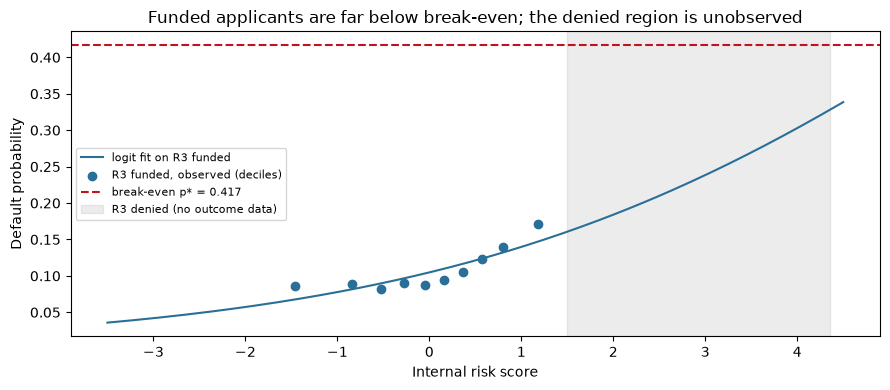


EXTRA: EXISTING CUSTOMERS
                      irs    credit  approve  default
existing_customer                                    
0                  0.1523  607.5120   0.7707   0.0723
1                 -0.2289  607.4056   0.8663   0.0912
existing_customer       0       1
irs_qr                           
1                  0.0530  0.0762
2                  0.0522  0.0786
3                  0.0565  0.0782
4                  0.0722  0.0970
5                  0.1160  0.1428
R1 IRS coefficient on existing_customer: -0.3834 | credit-score equivalent: 33.3 points


{'Intercept': 2.1934, 'C(regime)[T.R2]': -0.0649, 'C(regime)[T.R3]': 0.4883, 'credit_score': -0.0039, 'log_inc': -0.2293, 'existing_customer': 0.2089}


In [14]:
# Regime-adjusted score: remove each regime's average score offset so the same applicant gets the same score
# in every regime. R2 (loosest) funded applicants up to a higher adjusted score than R3 does, so R2 outcomes
# give real (not extrapolated) evidence on part of the R3 denied population.
offset = df.groupby("regime").irs_resid.mean()
print("regime score offsets (vs R1):", offset.round(3).to_dict())
df["s_adj"] = df.internal_risk_score - df.regime.map(offset)
f["s_adj"] = df.loc[f.index, "s_adj"]
r3d["s_adj"] = df.loc[r3d.index, "s_adj"]
print("max adjusted score among funded, by regime:", f.groupby("regime").s_adj.max().round(3).to_dict())
smax_r2 = f[f.regime == "R2"].s_adj.max()
ins = r3d[r3d.s_adj <= smax_r2]
print(f"R3 denied inside R2 funded support: {len(ins)} of {len(r3d)} ({len(ins)/len(r3d):.3f})")
f["s_band"] = pd.cut(f.s_adj, [-5, -1, 0, 0.5, 1, 1.25, 1.5, 1.75, 2.2])
sb = f.pivot_table(index="s_band", columns="regime", values="default_flag", aggfunc="mean", observed=True)
sb["n_R2"] = f[f.regime == "R2"].groupby("s_band", observed=True).size()
sb["R3/R2"] = sb.R3 / sb.R2
print(sb.round(3))
m_adj = smf.logit("default_flag ~ s_adj + C(regime)", f).fit(disp=0)
print("logit default ~ s_adj + regime:", m_adj.params.round(4).to_dict())
ins = ins.assign(p_r3=m_adj.predict(ins.assign(regime="R3")))
print("R3 denied, in R2 support: predicted R3 default mean %.3f, 95th pct %.3f, max %.3f" %
      (ins.p_r3.mean(), ins.p_r3.quantile(0.95), ins.p_r3.max()))
r2_top = f[(f.regime == "R2") & (f.s_adj > 1.5)]
print("R2 funded with adjusted score > 1.5 (would be denied in R3): n=%d default=%.3f; x R3/R2 shock 1.6 -> %.3f" %
      (len(r2_top), r2_top.default_flag.mean(), r2_top.default_flag.mean() * 1.6))
avg_price_req = r3d.device_requested.map(df.groupby("device_final").device_price.mean())
for lab, p in [("model", ins.p_r3), ("stress x1.5", ins.p_r3 * 1.5), ("stress x2", ins.p_r3 * 2)]:
    ev = (avg_price_req.loc[ins.index] * (0.25 - 0.60 * p)).sum()
    print(f"EV of approving in-support R3 denials ({lab}): ${ev:,.0f}  (${ev/len(ins):,.0f} each, mean p={p.mean():.3f})")

fig, ax = plt.subplots(figsize=(9, 4))
grp = r3f.groupby("irs_bin", observed=True).agg(x=("internal_risk_score", "mean"), d=("default_flag", "mean"))
xs = np.linspace(-3.5, 4.5, 200)
ax.plot(xs, 1 / (1 + np.exp(-(b0 + b1 * xs))), color="#2a6f97", label="logit fit on R3 funded")
ax.scatter(grp.x, grp.d, color="#2a6f97", zorder=3, label="R3 funded, observed (deciles)")
ax.axhline(p_star, color="#c1121f", ls="--", label=f"break-even p* = {p_star:.3f}")
ax.axvspan(r3d.internal_risk_score.min(), r3d.internal_risk_score.max(), color="grey", alpha=0.15, label="R3 denied (no outcome data)")
ax.set_xlabel("Internal risk score"); ax.set_ylabel("Default probability"); ax.legend(fontsize=8)
ax.set_title("Funded applicants are far below break-even; the denied region is unobserved")
fig.tight_layout(); plt.show()

# existing-customer check (supports Q6 features and Q8 'change who is approved')
section("EXTRA: EXISTING CUSTOMERS")
print(df.groupby("existing_customer").agg(irs=("internal_risk_score", "mean"), credit=("credit_score", "mean"),
                                          approve=("approve", "mean"), default=("default_flag", "mean")).round(4))
print(f.pivot_table(index="irs_qr", columns="existing_customer", values="default_flag", aggfunc="mean").round(4))
print("R1 IRS coefficient on existing_customer:", round(irs_fit.params["existing_customer"], 4),
      "| credit-score equivalent:", round(irs_fit.params["existing_customer"] / irs_fit.params["credit_score"], 1), "points")
print(smf.logit("default_flag ~ credit_score + log_inc + existing_customer + C(regime)", f).fit(disp=0).params.round(4).to_dict())